**Exploratory Data Analysis**

In [13]:
import pandas as pd
import os
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
data_path = os.path.join("..", "data")

csv_files = [
    "airportgroups.csv",
    "historical_flights.csv",
    "inference_data_oct2025.csv",
    "preds_mal.csv",
    "schedule_oct2025.csv",
    "training_data.csv"
]

# Dictionary to store DataFrames
dataframes = {}

# Read each CSV into a DataFrame
for file in csv_files:
    file_path = os.path.join(data_path, file)
    df_name = file.replace(".csv", "")
    dataframes[df_name] = pd.read_csv(file_path)
    
    print(f"\n=== {df_name} ===")
    print(dataframes[df_name].head(), "\n")


=== airportgroups ===
  airport_group airport
0             A     FDE
1             A     SDN
2             A     SOG
3             B     HOV
4             B     MOL 


=== historical_flights ===
  flight_id dep_airport dep_airport_group arr_airport arr_airport_group  \
0     WF149         HOV                 B         OSL               NaN   
1     WF722         OSL               NaN         MJF                 D   
2     WF188         FDE                 A         OSL               NaN   
3     WF176         HOV                 B         OSL               NaN   
4     WF148         HOV                 B         OSL               NaN   

  service_type                         std                         sta  \
0            J  2018-01-02T16:40:00.000000  2018-01-02T17:15:00.000000   
1            J  2018-01-28T13:04:00.000000  2018-01-28T14:50:00.000000   
2            J  2018-04-07T07:10:00.000000  2018-04-07T08:10:00.000000   
3            J  2018-04-07T11:00:00.000000  2018-04-07T1

In [15]:
# Let's examine the structure of each dataset
for name, df in dataframes.items():
    print(f"\n{'='*50}")
    print(f"Dataset: {name}")
    print(f"{'='*50}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {list(df.columns)}")
    print(f"Data types:\n{df.dtypes}")
    print(f"\nMissing values:\n{df.isnull().sum()}")
    if df.shape[0] > 0:
        print(f"\nFirst few rows:")
        print(df.head(3))
    print("\n")


Dataset: airportgroups
Shape: (21, 2)
Columns: ['airport_group', 'airport']
Data types:
airport_group    object
airport          object
dtype: object

Missing values:
airport_group    0
airport          0
dtype: int64

First few rows:
  airport_group airport
0             A     FDE
1             A     SDN
2             A     SOG



Dataset: historical_flights
Shape: (410442, 11)
Columns: ['flight_id', 'dep_airport', 'dep_airport_group', 'arr_airport', 'arr_airport_group', 'service_type', 'std', 'sta', 'cancelled', 'atd', 'ata']
Data types:
flight_id            object
dep_airport          object
dep_airport_group    object
arr_airport          object
arr_airport_group    object
service_type         object
std                  object
sta                  object
cancelled             int64
atd                  object
ata                  object
dtype: object

Missing values:
flight_id                 0
dep_airport               0
dep_airport_group    177474
arr_airport               0
ar

## Dataset Structure Overview

This analysis provides a comprehensive view of all datasets in the project. We examine the shape, columns, data types, and missing values for each dataset to understand the data structure and quality. This foundational analysis helps identify potential data issues early and informs our approach for feature engineering and modeling.

Training data shape: (465031, 8)


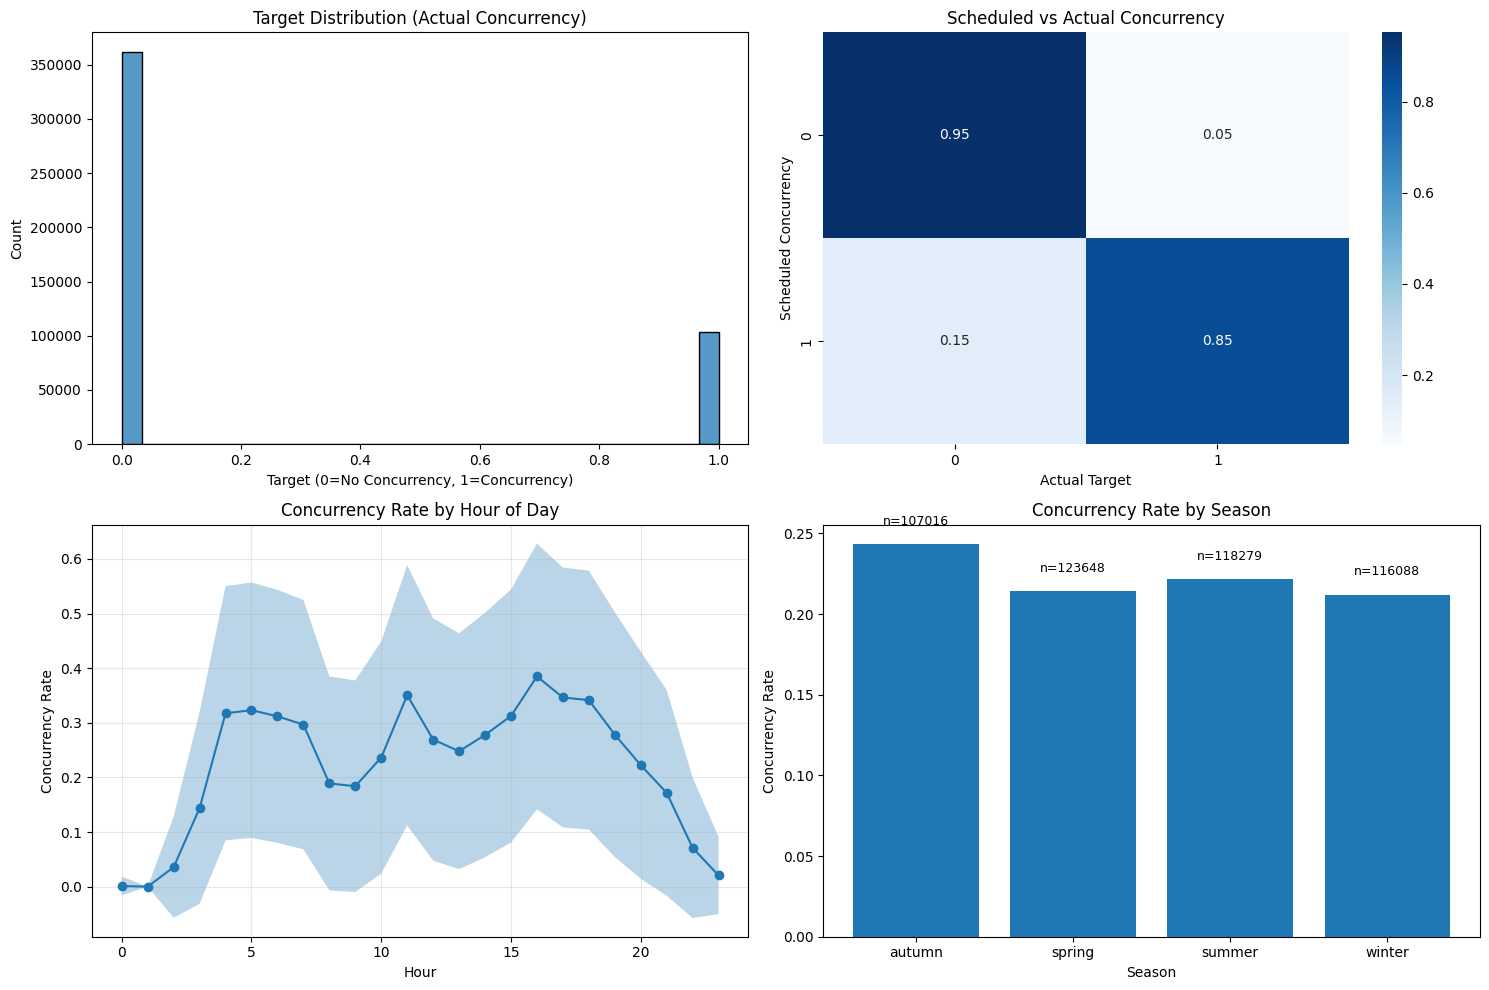

<Figure size 1500x600 with 0 Axes>

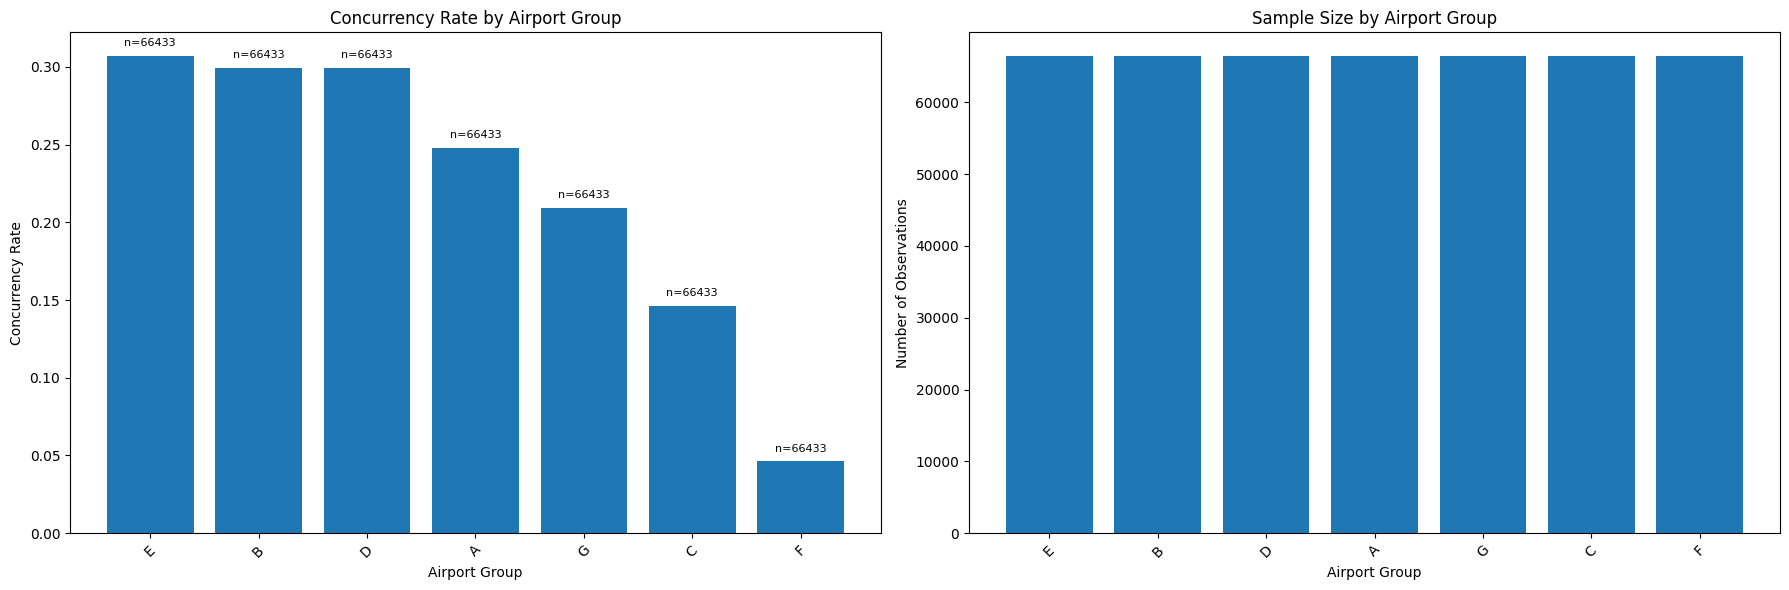

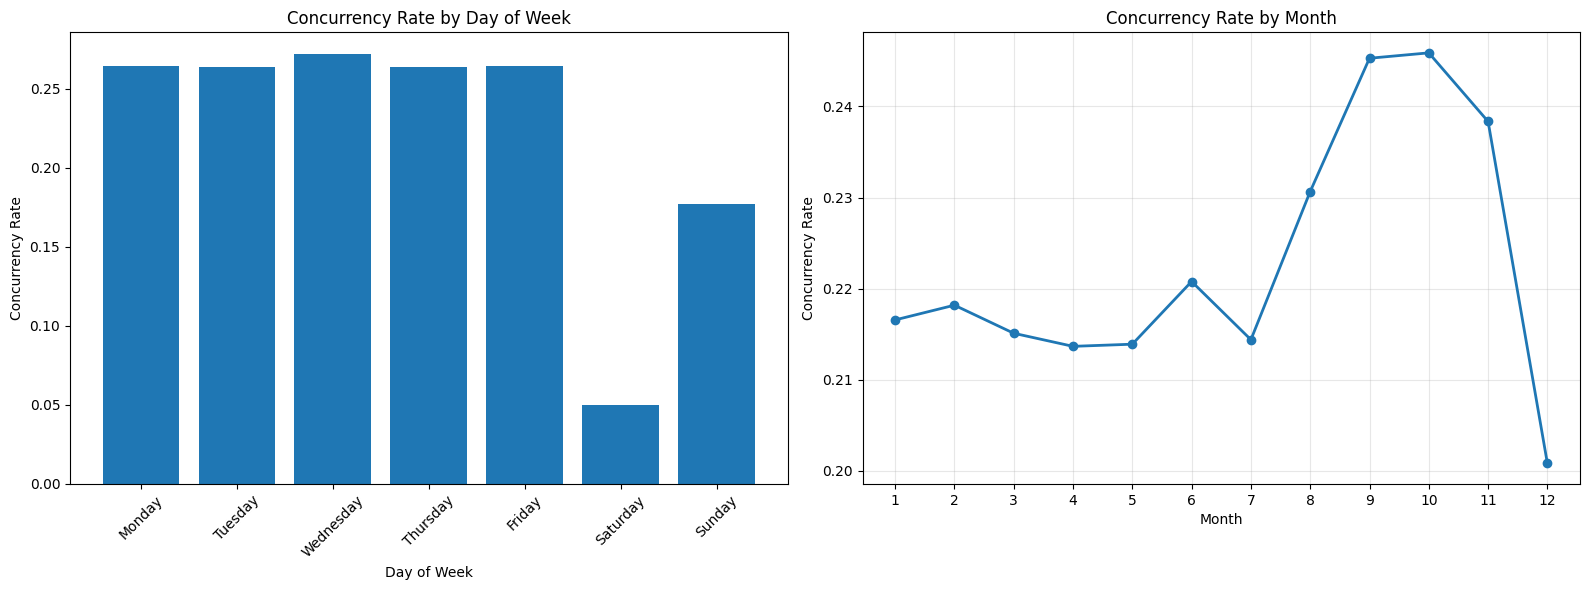

Overall concurrency rate: 0.222
Scheduled vs actual concurrency accuracy: 0.930


In [16]:
# ====================================================================================================
# TRAINING DATA ANALYSIS
# ====================================================================================================

df = dataframes["training_data"]
print(f"Training data shape: {df.shape}")

# 1. Target distribution and correlation
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Target distributions
sns.histplot(df["target"], bins=30, ax=axes[0,0])
axes[0,0].set_title("Target Distribution (Actual Concurrency)")
axes[0,0].set_xlabel("Target (0=No Concurrency, 1=Concurrency)")

# Target vs scheduled concurrency (feature importance)
confusion_data = pd.crosstab(df["feat_sched_concurrence"], df["target"], normalize='index')
sns.heatmap(confusion_data, annot=True, fmt='.2f', ax=axes[0,1], cmap='Blues')
axes[0,1].set_title("Scheduled vs Actual Concurrency")
axes[0,1].set_xlabel("Actual Target")
axes[0,1].set_ylabel("Scheduled Concurrency")

# Target by hour of day with confidence intervals
hourly_stats = df.groupby('hour')['target'].agg(['mean', 'std', 'count']).reset_index()
axes[1,0].plot(hourly_stats['hour'], hourly_stats['mean'], marker='o')
axes[1,0].fill_between(hourly_stats['hour'], 
                       hourly_stats['mean'] - hourly_stats['std']/2, 
                       hourly_stats['mean'] + hourly_stats['std']/2, alpha=0.3)
axes[1,0].set_title("Concurrency Rate by Hour of Day")
axes[1,0].set_xlabel("Hour")
axes[1,0].set_ylabel("Concurrency Rate")
axes[1,0].grid(True, alpha=0.3)

# Target by season with sample sizes
season_stats = df.groupby('feat_season')['target'].agg(['mean', 'count']).reset_index()
bars = axes[1,1].bar(season_stats['feat_season'], season_stats['mean'])
axes[1,1].set_title("Concurrency Rate by Season")
axes[1,1].set_xlabel("Season")
axes[1,1].set_ylabel("Concurrency Rate")
# Add sample size labels on bars
for i, (bar, count) in enumerate(zip(bars, season_stats['count'])):
    axes[1,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                   f'n={count}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# 2. Airport group analysis
plt.figure(figsize=(15, 6))

# Airport group analysis with sample sizes
airport_stats = df.groupby('airport_group')['target'].agg(['mean', 'count']).reset_index()
airport_stats = airport_stats.sort_values('mean', ascending=False)

# Create subplot for better visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Concurrency rate by airport group
bars1 = ax1.bar(range(len(airport_stats)), airport_stats['mean'])
ax1.set_title("Concurrency Rate by Airport Group")
ax1.set_xlabel("Airport Group")
ax1.set_ylabel("Concurrency Rate")
ax1.set_xticks(range(len(airport_stats)))
ax1.set_xticklabels(airport_stats['airport_group'], rotation=45)
# Add sample size labels
for i, (bar, count) in enumerate(zip(bars1, airport_stats['count'])):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
             f'n={count}', ha='center', va='bottom', fontsize=8)

# Sample size distribution by airport group
bars2 = ax2.bar(range(len(airport_stats)), airport_stats['count'])
ax2.set_title("Sample Size by Airport Group")
ax2.set_xlabel("Airport Group")
ax2.set_ylabel("Number of Observations")
ax2.set_xticks(range(len(airport_stats)))
ax2.set_xticklabels(airport_stats['airport_group'], rotation=45)

plt.tight_layout()
plt.show()

# 3. Temporal patterns
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Convert date to datetime for better analysis
df['date_parsed'] = pd.to_datetime(df['date'])
df['weekday'] = df['date_parsed'].dt.day_name()
df['month'] = df['date_parsed'].dt.month

# Weekday pattern
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_stats = df.groupby('weekday')['target'].agg(['mean', 'count']).reindex(weekday_order)
axes[0].bar(range(len(weekday_stats)), weekday_stats['mean'])
axes[0].set_title("Concurrency Rate by Day of Week")
axes[0].set_xlabel("Day of Week")
axes[0].set_ylabel("Concurrency Rate")
axes[0].set_xticks(range(len(weekday_stats)))
axes[0].set_xticklabels(weekday_stats.index, rotation=45)

# Monthly pattern
monthly_stats = df.groupby('month')['target'].agg(['mean', 'count'])
axes[1].plot(monthly_stats.index, monthly_stats['mean'], marker='o', linewidth=2)
axes[1].set_title("Concurrency Rate by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Concurrency Rate")
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(monthly_stats.index)

plt.tight_layout()
plt.show()

print(f"Overall concurrency rate: {df['target'].mean():.3f}")
print(f"Scheduled vs actual concurrency accuracy: {(df['feat_sched_concurrence'] == df['target']).mean():.3f}")

## Training Data Analysis Summary

This analysis reveals key patterns in our training data that will inform model development:

- **Target Distribution**: The data shows the balance between concurrency and non-concurrency events, helping us understand if we have a class imbalance problem.
- **Scheduled vs Actual Concurrency**: The heatmap shows how well scheduled concurrency predicts actual concurrency - this is crucial for understanding the baseline accuracy of our predictions.
- **Temporal Patterns**: Hour-by-hour and seasonal variations reveal when concurrency is most likely, which can be powerful predictive features.
- **Airport Group Variations**: Different airport groups show varying concurrency rates, indicating that location-specific models or features may be beneficial.
- **Day-of-Week and Monthly Trends**: These patterns can help capture cyclical behaviors in flight operations.

The overall concurrency rate and the accuracy of scheduled predictions provide important benchmarks for our machine learning models.

Historical flights shape: (410442, 11)


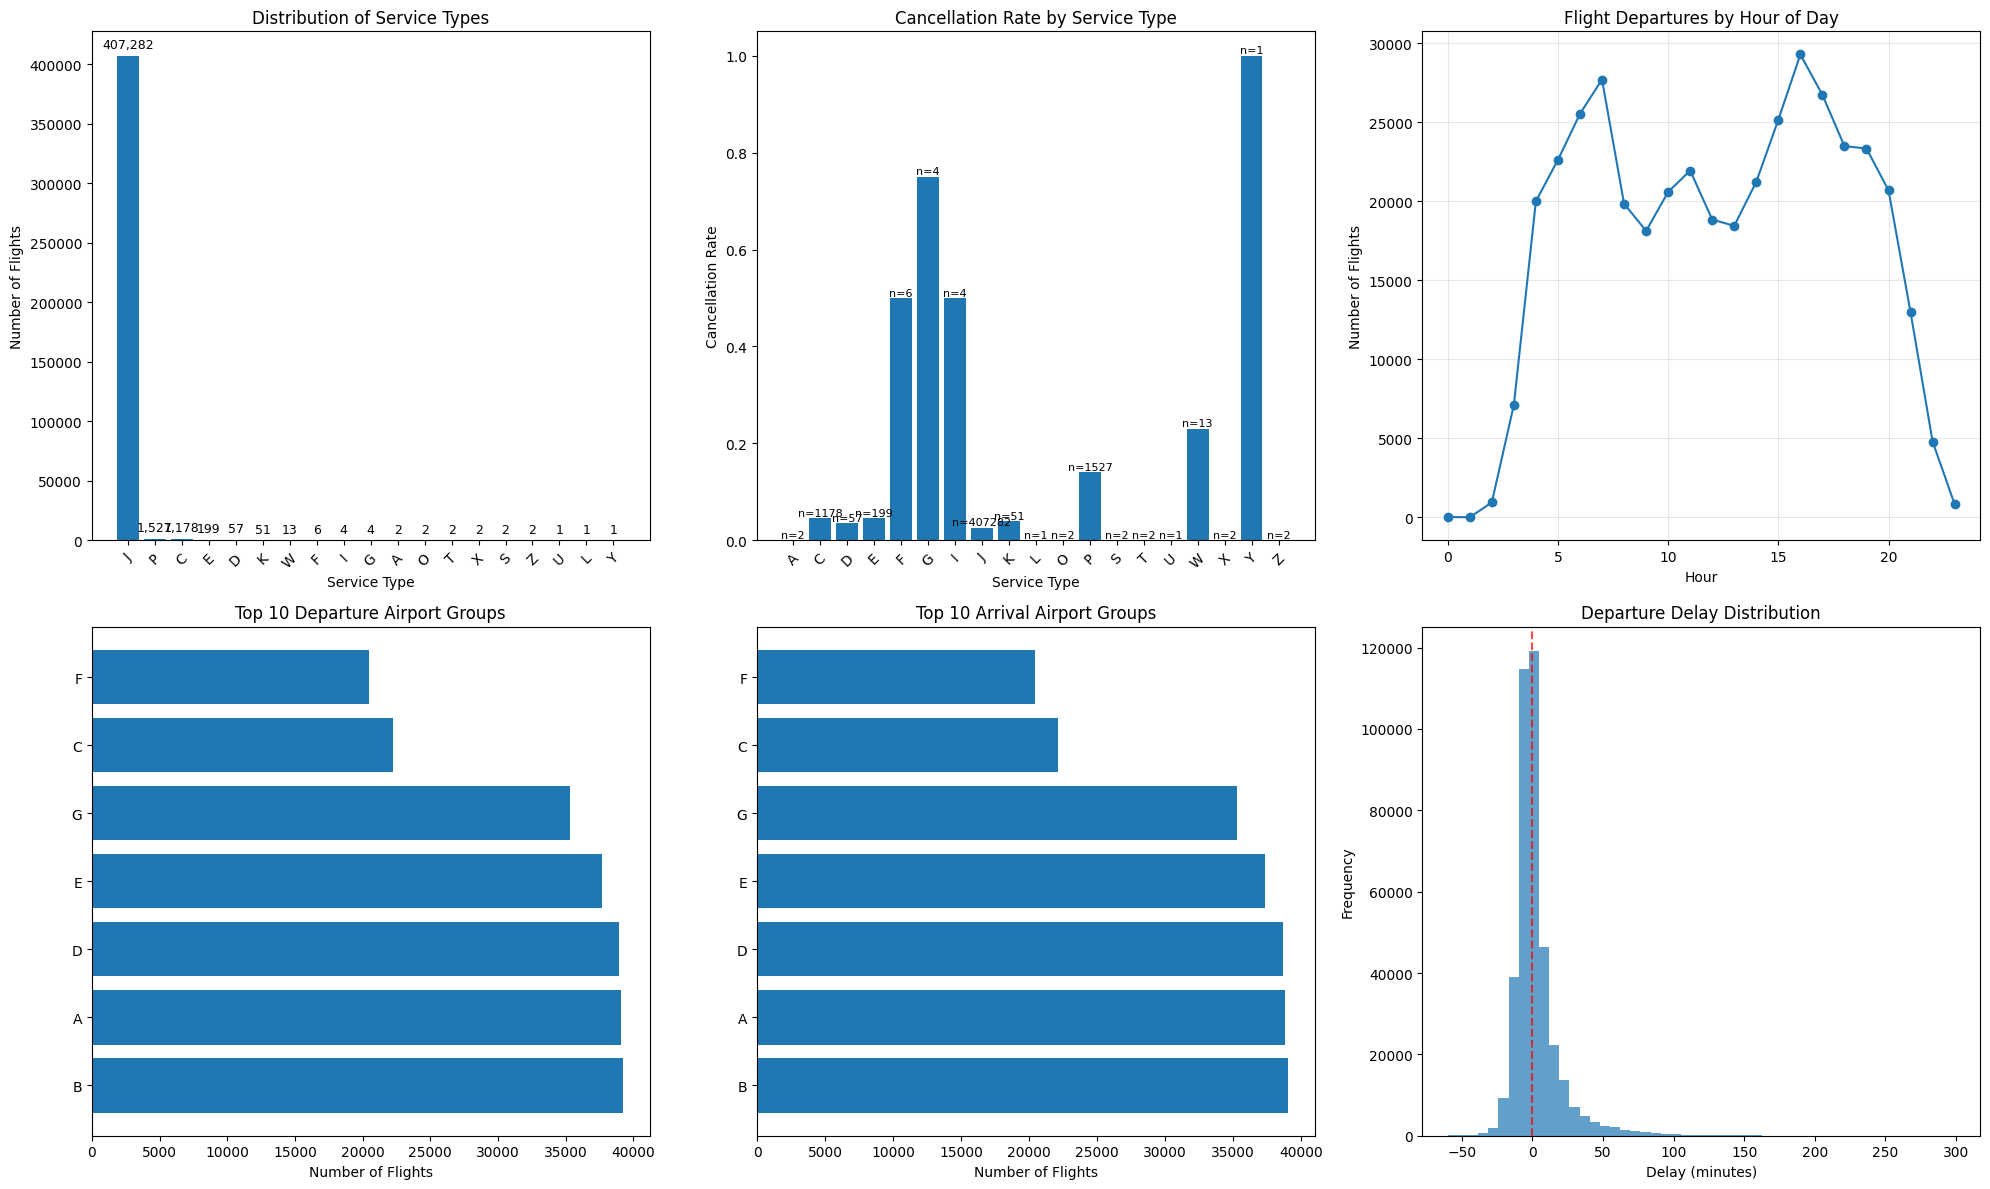

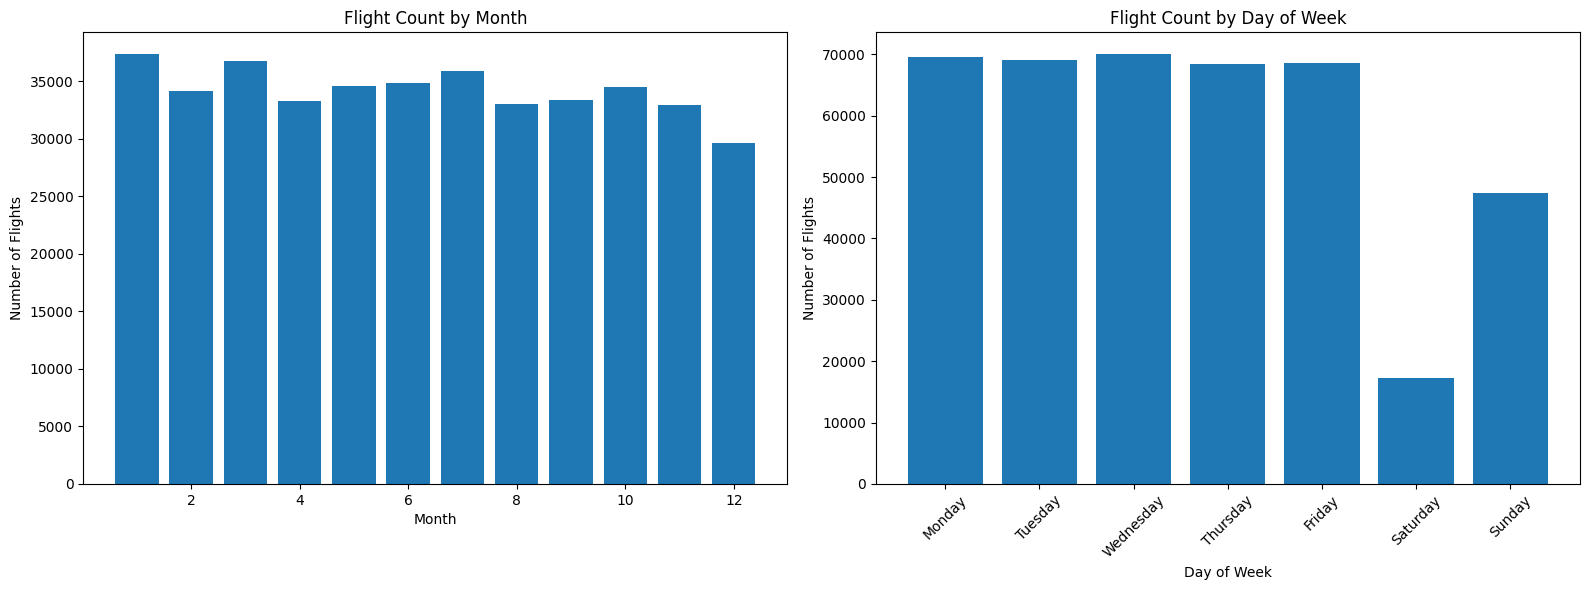

Total flights: 410,442
Date range: 2018-01-01 07:20:00 to 2025-07-31 21:40:00
Overall cancellation rate: 0.027
Average departure delay: 2.6 minutes


In [17]:
# ====================================================================================================
# HISTORICAL FLIGHTS ANALYSIS
# ====================================================================================================

df_hist = dataframes["historical_flights"]
print(f"Historical flights shape: {df_hist.shape}")

# Convert datetime columns
df_hist['std'] = pd.to_datetime(df_hist['std'])
df_hist['sta'] = pd.to_datetime(df_hist['sta'])
if 'atd' in df_hist.columns:
    df_hist['atd'] = pd.to_datetime(df_hist['atd'])
if 'ata' in df_hist.columns:
    df_hist['ata'] = pd.to_datetime(df_hist['ata'])

# Calculate delays if actual times are available
if 'atd' in df_hist.columns and 'std' in df_hist.columns:
    df_hist['dep_delay'] = (df_hist['atd'] - df_hist['std']).dt.total_seconds() / 60  # in minutes

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# 1. Service type distribution
service_counts = df_hist['service_type'].value_counts()
# Use bar chart instead of pie chart for better readability
bars = axes[0,0].bar(range(len(service_counts)), service_counts.values)
axes[0,0].set_title("Distribution of Service Types")
axes[0,0].set_xlabel("Service Type")
axes[0,0].set_ylabel("Number of Flights")
axes[0,0].set_xticks(range(len(service_counts)))
axes[0,0].set_xticklabels(service_counts.index, rotation=45)
# Add values on bars for exact counts
for i, (bar, value) in enumerate(zip(bars, service_counts.values)):
    axes[0,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(service_counts.values)*0.01, 
                   f'{value:,}', ha='center', va='bottom', fontsize=9)

# 2. Cancellation rate by service type
if 'cancelled' in df_hist.columns:
    cancel_by_service = df_hist.groupby('service_type')['cancelled'].agg(['mean', 'count'])
    bars = axes[0,1].bar(range(len(cancel_by_service)), cancel_by_service['mean'])
    axes[0,1].set_title("Cancellation Rate by Service Type")
    axes[0,1].set_xlabel("Service Type")
    axes[0,1].set_ylabel("Cancellation Rate")
    axes[0,1].set_xticks(range(len(cancel_by_service)))
    axes[0,1].set_xticklabels(cancel_by_service.index, rotation=45)
    # Add sample sizes
    for i, (bar, count) in enumerate(zip(bars, cancel_by_service['count'])):
        axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, 
                       f'n={count}', ha='center', va='bottom', fontsize=8)

# 3. Flight activity by hour
df_hist['dep_hour'] = df_hist['std'].dt.hour
hourly_flights = df_hist['dep_hour'].value_counts().sort_index()
axes[0,2].plot(hourly_flights.index, hourly_flights.values, marker='o')
axes[0,2].set_title("Flight Departures by Hour of Day")
axes[0,2].set_xlabel("Hour")
axes[0,2].set_ylabel("Number of Flights")
axes[0,2].grid(True, alpha=0.3)

# 4. Top departure airport groups
dep_groups = df_hist['dep_airport_group'].value_counts().head(10)
axes[1,0].barh(range(len(dep_groups)), dep_groups.values)
axes[1,0].set_title("Top 10 Departure Airport Groups")
axes[1,0].set_xlabel("Number of Flights")
axes[1,0].set_yticks(range(len(dep_groups)))
axes[1,0].set_yticklabels(dep_groups.index)

# 5. Top arrival airport groups
arr_groups = df_hist['arr_airport_group'].value_counts().head(10)
axes[1,1].barh(range(len(arr_groups)), arr_groups.values)
axes[1,1].set_title("Top 10 Arrival Airport Groups")
axes[1,1].set_xlabel("Number of Flights")
axes[1,1].set_yticks(range(len(arr_groups)))
axes[1,1].set_yticklabels(arr_groups.index)

# 6. Delay distribution (if available)
if 'dep_delay' in df_hist.columns:
    delay_data = df_hist['dep_delay'].dropna()
    delay_data = delay_data[(delay_data >= -60) & (delay_data <= 300)]  # Filter extreme outliers
    axes[1,2].hist(delay_data, bins=50, alpha=0.7)
    axes[1,2].set_title("Departure Delay Distribution")
    axes[1,2].set_xlabel("Delay (minutes)")
    axes[1,2].set_ylabel("Frequency")
    axes[1,2].axvline(0, color='red', linestyle='--', alpha=0.7)
else:
    axes[1,2].text(0.5, 0.5, "Actual departure times\nnot available", 
                   ha='center', va='center', transform=axes[1,2].transAxes)
    axes[1,2].set_title("Departure Delays")

plt.tight_layout()
plt.show()

# Flight patterns by month and weekday
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Monthly pattern
df_hist['month'] = df_hist['std'].dt.month
monthly_flights = df_hist['month'].value_counts().sort_index()
axes[0].bar(monthly_flights.index, monthly_flights.values)
axes[0].set_title("Flight Count by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Flights")

# Weekday pattern
df_hist['weekday'] = df_hist['std'].dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_flights = df_hist['weekday'].value_counts().reindex(weekday_order)
axes[1].bar(range(len(weekday_flights)), weekday_flights.values)
axes[1].set_title("Flight Count by Day of Week")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Number of Flights")
axes[1].set_xticks(range(len(weekday_flights)))
axes[1].set_xticklabels(weekday_flights.index, rotation=45)

plt.tight_layout()
plt.show()

print(f"Total flights: {len(df_hist):,}")
print(f"Date range: {df_hist['std'].min()} to {df_hist['std'].max()}")
if 'cancelled' in df_hist.columns:
    print(f"Overall cancellation rate: {df_hist['cancelled'].mean():.3f}")
if 'dep_delay' in df_hist.columns:
    print(f"Average departure delay: {df_hist['dep_delay'].mean():.1f} minutes")

## Historical Flights Analysis Summary

This comprehensive analysis of historical flight data provides crucial context for understanding flight operations:

- **Service Type Distribution**: Shows the mix of different flight types (commercial, charter, cargo, etc.) which may have different concurrency patterns.
- **Cancellation Patterns**: Identifies which service types are most prone to cancellations, which could affect concurrency predictions.
- **Temporal Flight Patterns**: Hour-by-hour, daily, and monthly flight distributions reveal operational rhythms that influence airport congestion.
- **Airport Group Activity**: Identifies the busiest departure and arrival airport groups, which are likely to experience more concurrency issues.
- **Delay Analysis**: When available, departure delay distributions help understand operational efficiency and potential for schedule disruptions.

This historical context is essential for feature engineering - patterns observed here can be used to create predictive features for the October 2025 concurrency prediction task.

October 2025 schedule shape: (3984, 8)


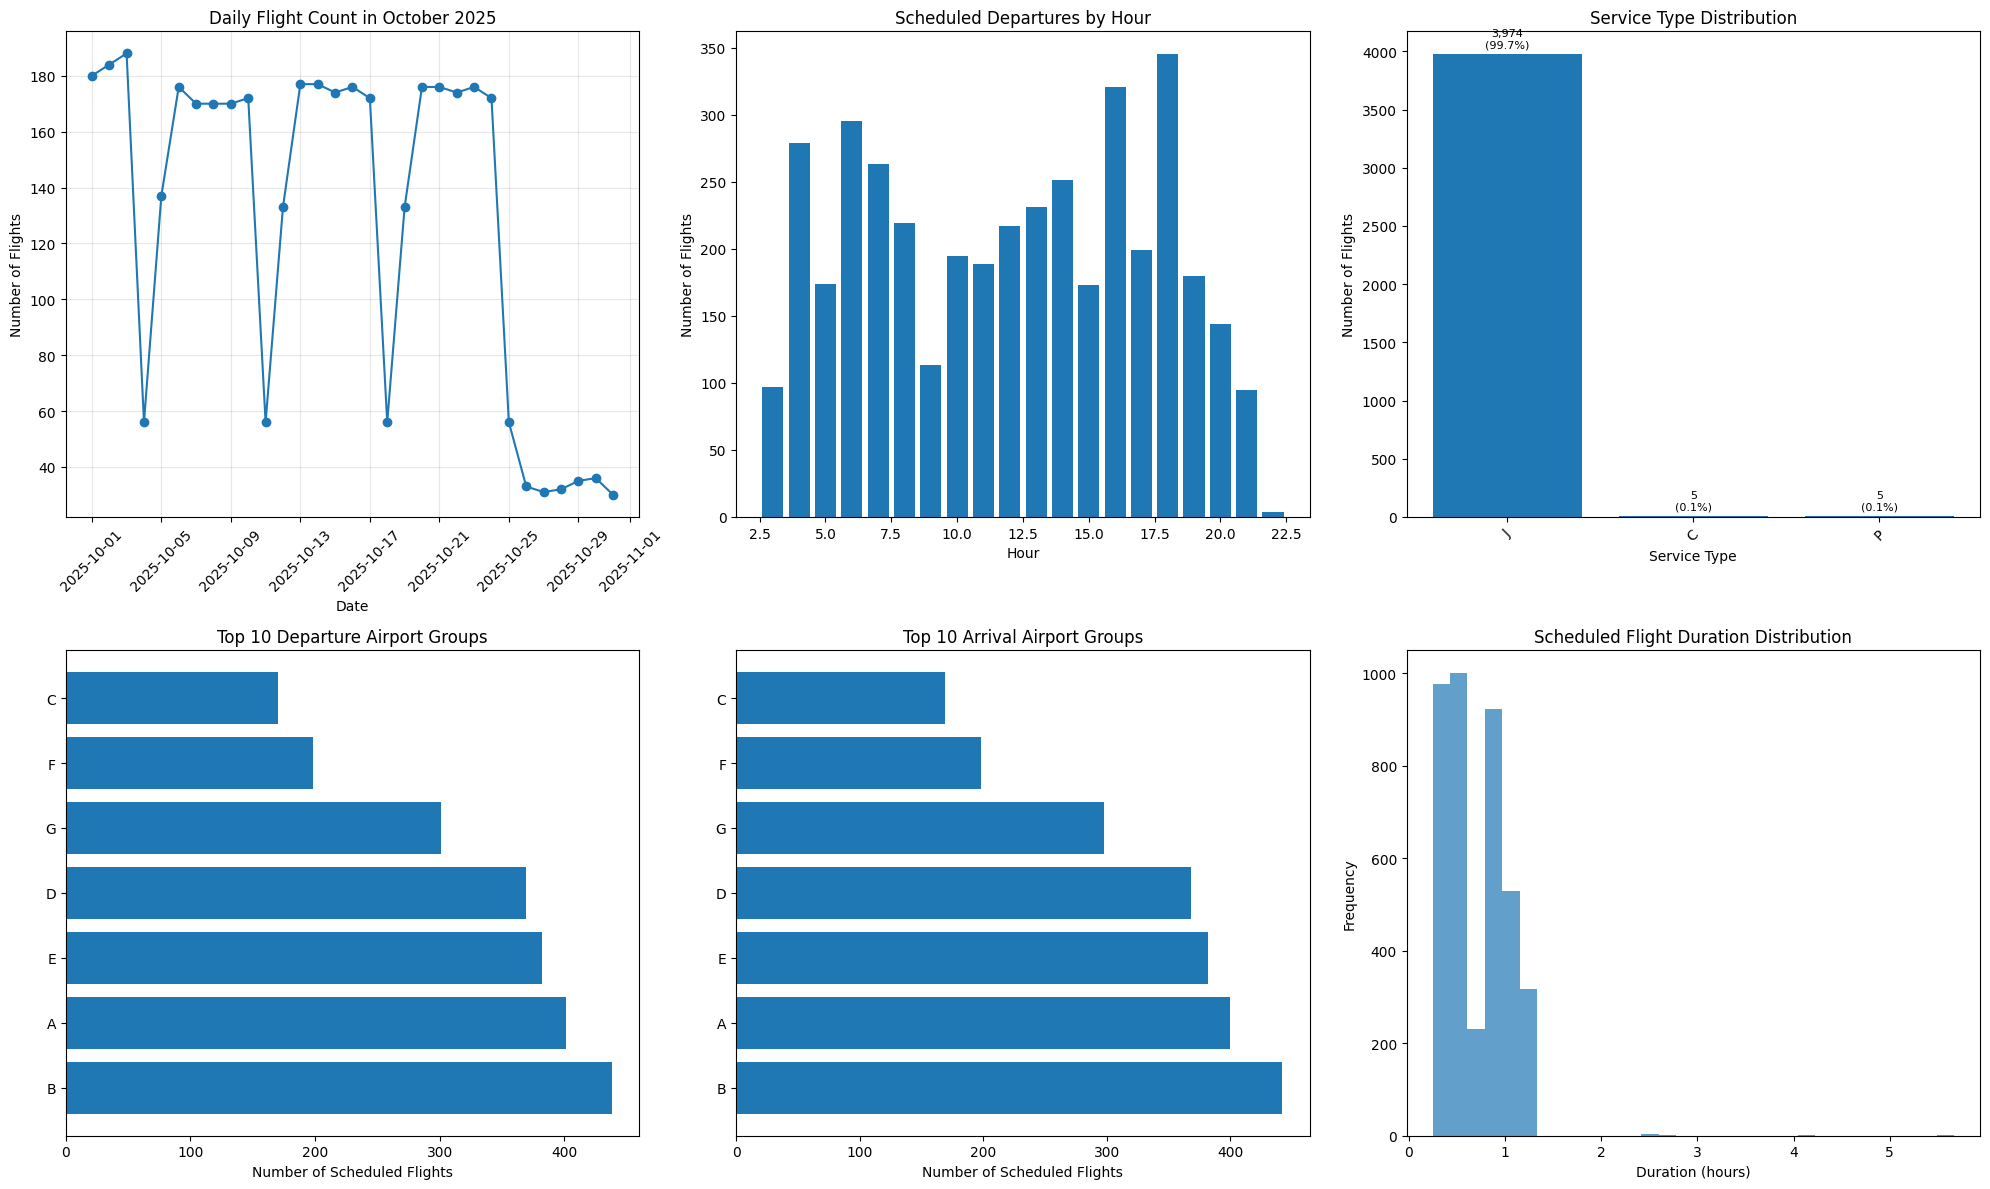

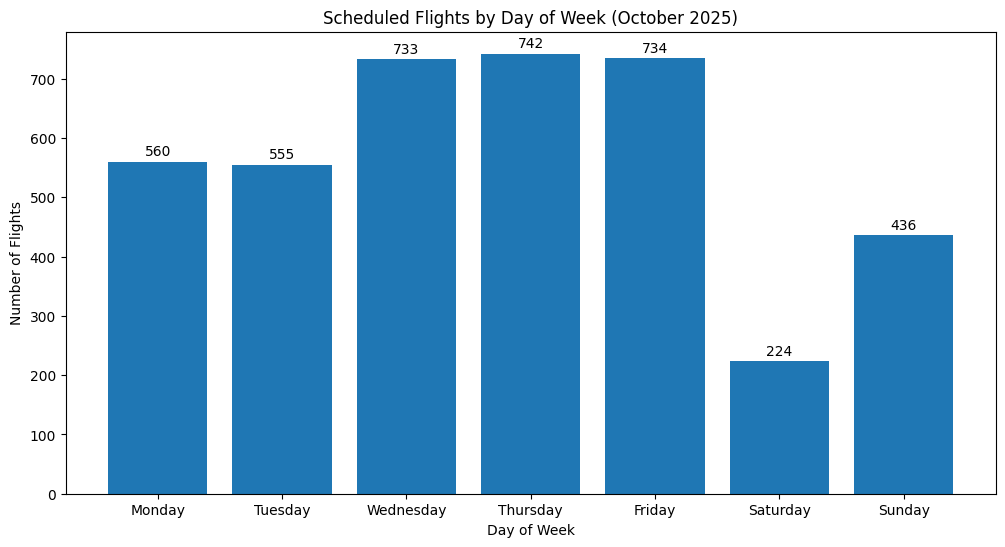

Total scheduled flights in October 2025: 3,984
Date range: 2025-10-01 03:00:00 to 2025-10-31 20:25:00
Average flights per day: 128.5
Unique departure airports: 32
Unique arrival airports: 32
Average flight duration: 0.7 hours


In [18]:
# ====================================================================================================
# OCTOBER 2025 SCHEDULE ANALYSIS
# ====================================================================================================

df_sched = dataframes["schedule_oct2025"]
print(f"October 2025 schedule shape: {df_sched.shape}")

# Convert datetime columns
df_sched['std'] = pd.to_datetime(df_sched['std'])
df_sched['sta'] = pd.to_datetime(df_sched['sta'])
df_sched['dep_hour'] = df_sched['std'].dt.hour
df_sched['dep_date'] = df_sched['std'].dt.date

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# 1. Daily flight distribution
daily_flights = df_sched.groupby('dep_date').size()
axes[0,0].plot(daily_flights.index, daily_flights.values, marker='o')
axes[0,0].set_title("Daily Flight Count in October 2025")
axes[0,0].set_xlabel("Date")
axes[0,0].set_ylabel("Number of Flights")
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].grid(True, alpha=0.3)

# 2. Hourly flight distribution
hourly_flights = df_sched['dep_hour'].value_counts().sort_index()
axes[0,1].bar(hourly_flights.index, hourly_flights.values)
axes[0,1].set_title("Scheduled Departures by Hour")
axes[0,1].set_xlabel("Hour")
axes[0,1].set_ylabel("Number of Flights")

# 3. Service type distribution
service_dist = df_sched['service_type'].value_counts()
# Use bar chart instead of pie chart for better readability with imbalanced data
bars = axes[0,2].bar(range(len(service_dist)), service_dist.values)
axes[0,2].set_title("Service Type Distribution")
axes[0,2].set_xlabel("Service Type")
axes[0,2].set_ylabel("Number of Flights")
axes[0,2].set_xticks(range(len(service_dist)))
axes[0,2].set_xticklabels(service_dist.index, rotation=45)
# Add percentage labels on bars
total_flights = service_dist.sum()
for i, (bar, value) in enumerate(zip(bars, service_dist.values)):
    pct = (value / total_flights) * 100
    axes[0,2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(service_dist.values)*0.01, 
                   f'{value:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=8)

# 4. Top departure airport groups
dep_groups = df_sched['dep_airport_group'].value_counts().head(10)
axes[1,0].barh(range(len(dep_groups)), dep_groups.values)
axes[1,0].set_title("Top 10 Departure Airport Groups")
axes[1,0].set_xlabel("Number of Scheduled Flights")
axes[1,0].set_yticks(range(len(dep_groups)))
axes[1,0].set_yticklabels(dep_groups.index)

# 5. Top arrival airport groups
arr_groups = df_sched['arr_airport_group'].value_counts().head(10)
axes[1,1].barh(range(len(arr_groups)), arr_groups.values)
axes[1,1].set_title("Top 10 Arrival Airport Groups")
axes[1,1].set_xlabel("Number of Scheduled Flights")
axes[1,1].set_yticks(range(len(arr_groups)))
axes[1,1].set_yticklabels(arr_groups.index)

# 6. Flight duration distribution
df_sched['flight_duration'] = (df_sched['sta'] - df_sched['std']).dt.total_seconds() / 3600  # in hours
duration_data = df_sched['flight_duration'].dropna()
duration_data = duration_data[duration_data > 0]  # Remove negative durations
axes[1,2].hist(duration_data, bins=30, alpha=0.7)
axes[1,2].set_title("Scheduled Flight Duration Distribution")
axes[1,2].set_xlabel("Duration (hours)")
axes[1,2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Weekday pattern analysis
df_sched['weekday'] = df_sched['std'].dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_flights = df_sched['weekday'].value_counts().reindex(weekday_order)

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(weekday_flights)), weekday_flights.values)
plt.title("Scheduled Flights by Day of Week (October 2025)")
plt.xlabel("Day of Week")
plt.ylabel("Number of Flights")
plt.xticks(range(len(weekday_flights)), weekday_flights.index)
# Add values on bars
for bar, value in zip(bars, weekday_flights.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
             str(value), ha='center', va='bottom')
plt.show()

print(f"Total scheduled flights in October 2025: {len(df_sched):,}")
print(f"Date range: {df_sched['std'].min()} to {df_sched['std'].max()}")
print(f"Average flights per day: {len(df_sched) / df_sched['dep_date'].nunique():.1f}")
print(f"Unique departure airports: {df_sched['dep_airport'].nunique()}")
print(f"Unique arrival airports: {df_sched['arr_airport'].nunique()}")
print(f"Average flight duration: {duration_data.mean():.1f} hours")

## October 2025 Schedule Analysis Summary

This analysis examines the scheduled flights for October 2025, which forms the basis for our prediction task:

- **Daily Flight Patterns**: Shows how flight volume varies throughout the month, helping identify potential high-concurrency days.
- **Hourly Distribution**: Reveals peak operational hours when concurrency is most likely to occur.
- **Service Type Mix**: Compares the service type distribution to historical data to identify any changes in flight patterns.
- **Airport Group Activity**: Identifies which airport groups will be busiest in October 2025, focusing our attention on high-risk areas.
- **Flight Duration Patterns**: Understanding typical flight durations helps assess airport resource utilization.
- **Weekly Patterns**: Day-of-week variations show operational rhythms that affect concurrency likelihood.

This forward-looking analysis helps us understand the operational context we'll be predicting for and ensures our models are calibrated for October 2025 conditions rather than just historical patterns.

Inference data shape: (5208, 6)


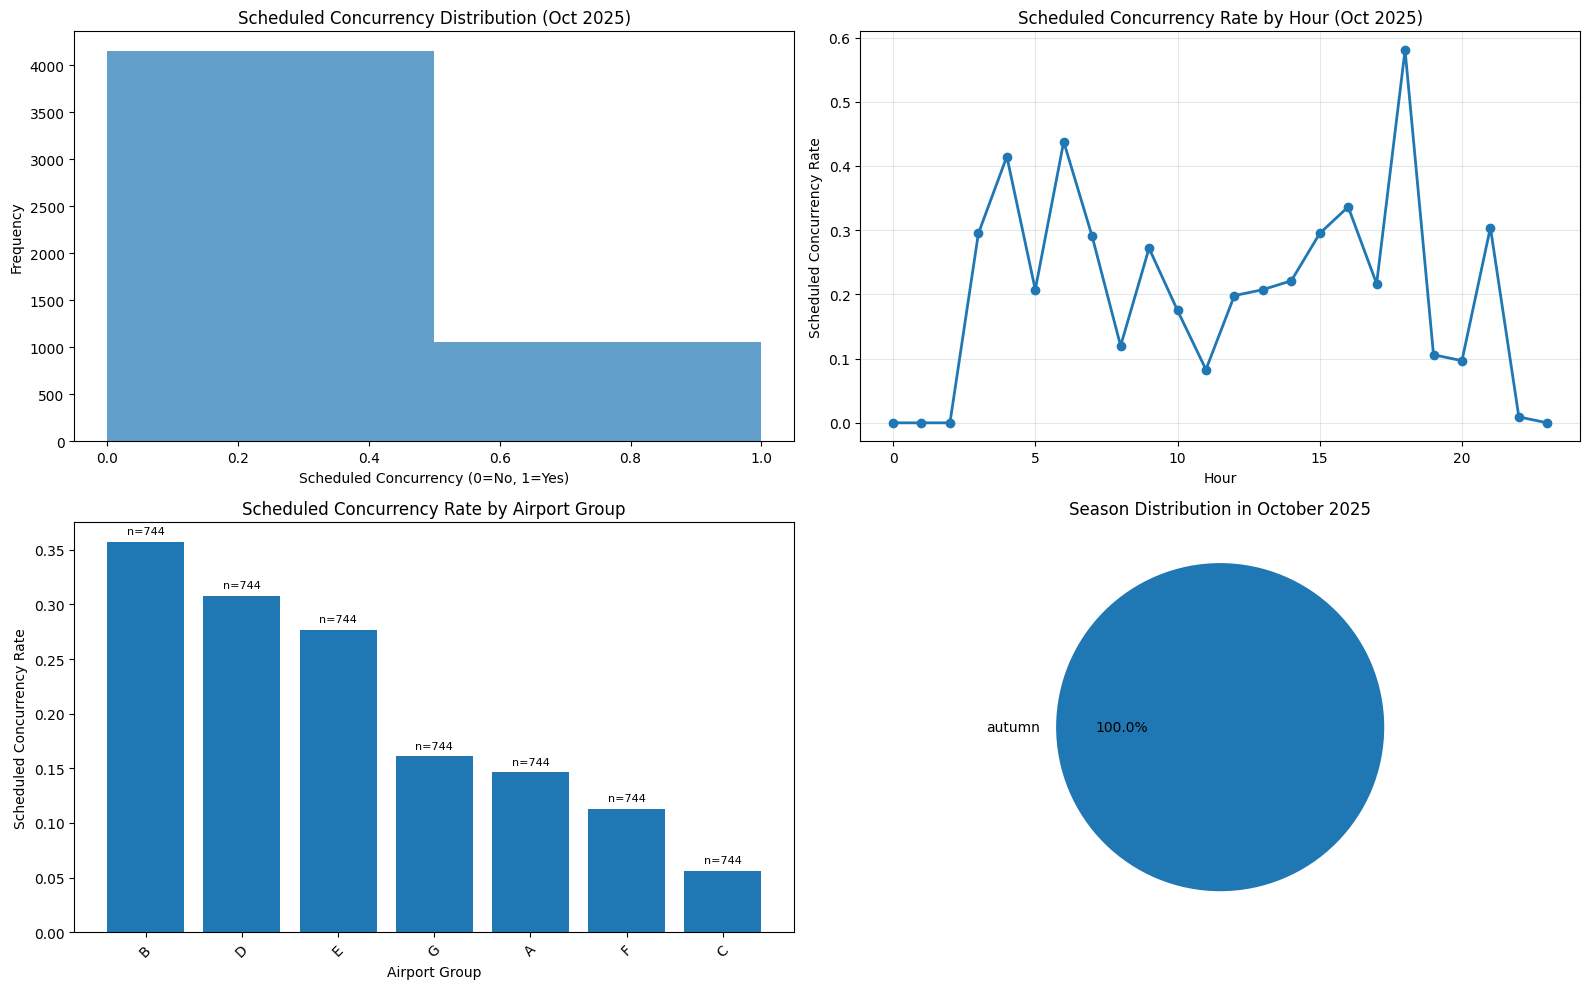

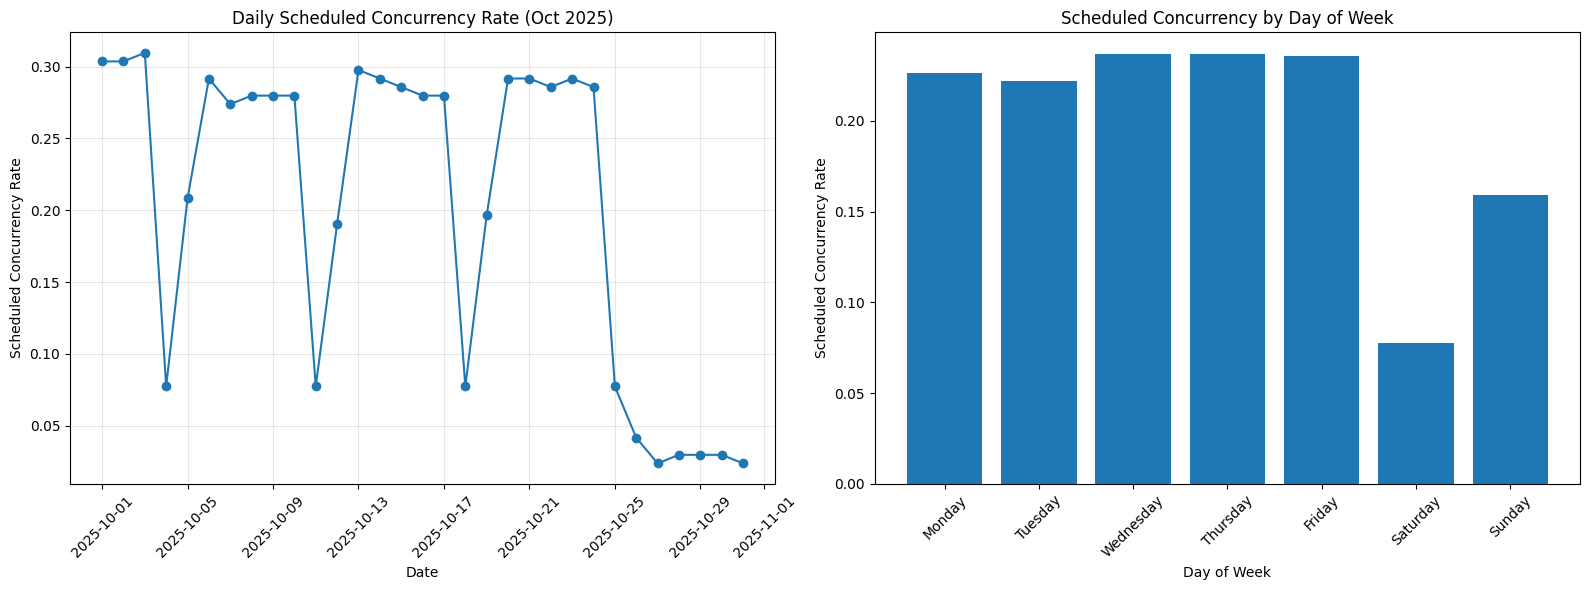

Total prediction instances: 5,208
Date range: 2025-10-01 to 2025-10-31
Overall scheduled concurrency rate: 0.203
Number of airport groups: 7
Hours covered: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [19]:
# ====================================================================================================
# INFERENCE DATA OCTOBER 2025 ANALYSIS
# ====================================================================================================

df_inf = dataframes["inference_data_oct2025"]
print(f"Inference data shape: {df_inf.shape}")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Scheduled concurrency distribution
axes[0,0].hist(df_inf["feat_sched_concurrence"], bins=2, alpha=0.7)
axes[0,0].set_title("Scheduled Concurrency Distribution (Oct 2025)")
axes[0,0].set_xlabel("Scheduled Concurrency (0=No, 1=Yes)")
axes[0,0].set_ylabel("Frequency")

# 2. Scheduled concurrency by hour
hourly_conc = df_inf.groupby('hour')['feat_sched_concurrence'].agg(['mean', 'count'])
axes[0,1].plot(hourly_conc.index, hourly_conc['mean'], marker='o', linewidth=2)
axes[0,1].set_title("Scheduled Concurrency Rate by Hour (Oct 2025)")
axes[0,1].set_xlabel("Hour")
axes[0,1].set_ylabel("Scheduled Concurrency Rate")
axes[0,1].grid(True, alpha=0.3)

# 3. Scheduled concurrency by airport group
airport_conc = df_inf.groupby('airport_group')['feat_sched_concurrence'].agg(['mean', 'count']).reset_index()
airport_conc = airport_conc.sort_values('mean', ascending=False)
bars = axes[1,0].bar(range(len(airport_conc)), airport_conc['mean'])
axes[1,0].set_title("Scheduled Concurrency Rate by Airport Group")
axes[1,0].set_xlabel("Airport Group")
axes[1,0].set_ylabel("Scheduled Concurrency Rate")
axes[1,0].set_xticks(range(len(airport_conc)))
axes[1,0].set_xticklabels(airport_conc['airport_group'], rotation=45)
# Add sample sizes
for i, (bar, count) in enumerate(zip(bars, airport_conc['count'])):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
                   f'n={count}', ha='center', va='bottom', fontsize=8)

# 4. Season distribution in October
season_dist = df_inf['feat_season'].value_counts()
axes[1,1].pie(season_dist.values, labels=season_dist.index, autopct='%1.1f%%')
axes[1,1].set_title("Season Distribution in October 2025")

plt.tight_layout()
plt.show()

# Daily and weekday patterns
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Convert date for temporal analysis
df_inf['date_parsed'] = pd.to_datetime(df_inf['date'])
df_inf['weekday'] = df_inf['date_parsed'].dt.day_name()

# Daily scheduled concurrency
daily_conc = df_inf.groupby('date')['feat_sched_concurrence'].mean()
axes[0].plot(pd.to_datetime(daily_conc.index), daily_conc.values, marker='o')
axes[0].set_title("Daily Scheduled Concurrency Rate (Oct 2025)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Scheduled Concurrency Rate")
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# Weekday scheduled concurrency
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_conc = df_inf.groupby('weekday')['feat_sched_concurrence'].agg(['mean', 'count']).reindex(weekday_order)
bars = axes[1].bar(range(len(weekday_conc)), weekday_conc['mean'])
axes[1].set_title("Scheduled Concurrency by Day of Week")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Scheduled Concurrency Rate")
axes[1].set_xticks(range(len(weekday_conc)))
axes[1].set_xticklabels(weekday_conc.index, rotation=45)

plt.tight_layout()
plt.show()

print(f"Total prediction instances: {len(df_inf):,}")
print(f"Date range: {df_inf['date'].min()} to {df_inf['date'].max()}")
print(f"Overall scheduled concurrency rate: {df_inf['feat_sched_concurrence'].mean():.3f}")
print(f"Number of airport groups: {df_inf['airport_group'].nunique()}")
print(f"Hours covered: {sorted(df_inf['hour'].unique())}")

## Inference Data Analysis Summary

This analysis examines the specific data points where we need to make concurrency predictions for October 2025:

- **Scheduled Concurrency Baseline**: Shows the distribution of scheduled concurrency predictions, which serves as our baseline model performance.
- **Temporal Prediction Patterns**: Reveals when and where concurrency predictions are needed, helping us understand the scope of our prediction task.
- **Airport Group Coverage**: Ensures we have prediction targets for all relevant airport groups and identifies which groups will require the most predictions.
- **Seasonal Context**: Confirms the seasonal features available for October 2025 predictions.
- **Daily and Weekly Patterns**: Shows the temporal distribution of prediction instances, helping us understand if certain days or times require more attention.

This analysis confirms that our prediction dataset is well-structured and covers the appropriate time periods and locations. The scheduled concurrency rate provides a meaningful baseline that our machine learning models should aim to exceed.

Airport groups shape: (21, 2)

Airport Groups Mapping:
airport_group: ['A', 'A', 'A', 'B', 'B', 'B', 'C', 'C', 'C', 'D', 'D', 'D', 'E', 'E', 'E', 'F', 'F', 'F', 'G', 'G', 'G']
airport: ['FDE', 'SDN', 'SOG', 'HOV', 'MOL', 'RRS', 'OSY', 'RVK', 'SOJ', 'MJF', 'MQN', 'SSJ', 'LKN', 'RET', 'SVJ', 'BJF', 'BVG', 'VAW', 'HAA', 'MEH', 'VDS']


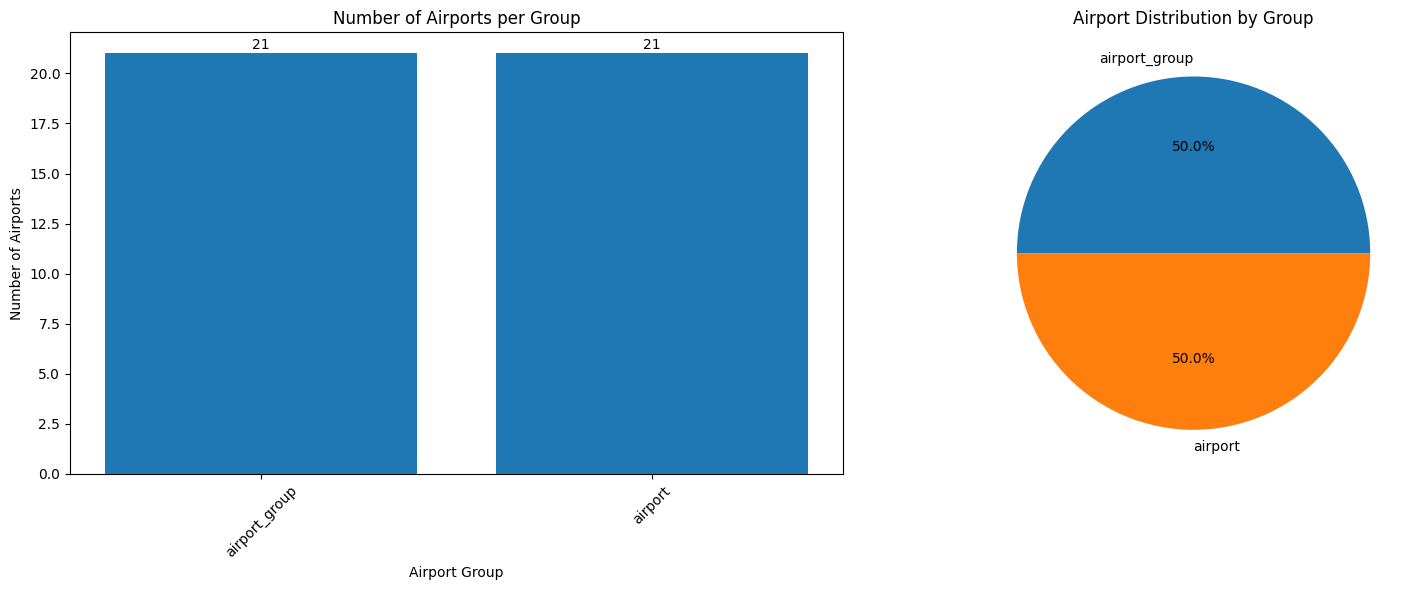


Total unique airports: 42
Number of airport groups: 2
Average airports per group: 21.0

Example airport mappings:
  A -> airport_group
  B -> airport_group
  C -> airport_group
  D -> airport_group
  E -> airport_group
  F -> airport_group
  G -> airport_group
  FDE -> airport
  SDN -> airport
  SOG -> airport
  ... and 18 more


In [20]:
# ====================================================================================================
# AIRPORT GROUPS ANALYSIS
# ====================================================================================================

df_airports = dataframes["airportgroups"]
print(f"Airport groups shape: {df_airports.shape}")

# Display the airport groups mapping
print("\nAirport Groups Mapping:")
print("="*50)
for group in df_airports.columns:
    airports = df_airports[group].dropna().tolist()
    print(f"{group}: {airports}")

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Number of airports per group
group_sizes = {}
for group in df_airports.columns:
    group_sizes[group] = df_airports[group].count()

bars = axes[0].bar(group_sizes.keys(), group_sizes.values())
axes[0].set_title("Number of Airports per Group")
axes[0].set_xlabel("Airport Group")
axes[0].set_ylabel("Number of Airports")
axes[0].tick_params(axis='x', rotation=45)
# Add values on bars
for bar, value in zip(bars, group_sizes.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, 
                 str(value), ha='center', va='bottom')

# 2. Airport distribution by group (pie chart)
axes[1].pie(group_sizes.values(), labels=group_sizes.keys(), autopct='%1.1f%%')
axes[1].set_title("Airport Distribution by Group")

plt.tight_layout()
plt.show()

# Show detailed airport listings
print(f"\nTotal unique airports: {sum(group_sizes.values())}")
print(f"Number of airport groups: {len(group_sizes)}")
print(f"Average airports per group: {sum(group_sizes.values()) / len(group_sizes):.1f}")

# Create a mapping dictionary for future use
airport_to_group = {}
for group in df_airports.columns:
    for airport in df_airports[group].dropna():
        airport_to_group[airport] = group
        
print(f"\nExample airport mappings:")
for i, (airport, group) in enumerate(list(airport_to_group.items())[:10]):
    print(f"  {airport} -> {group}")
if len(airport_to_group) > 10:
    print(f"  ... and {len(airport_to_group) - 10} more")

## Airport Groups Analysis Summary

This analysis provides essential context about the airport grouping structure used throughout the project:

- **Group Composition**: Shows how individual airports are organized into groups, which is fundamental to understanding the prediction task since we predict concurrency at the group level, not individual airports.
- **Group Size Distribution**: Reveals whether airport groups are balanced in size or if some groups contain significantly more airports than others.
- **Mapping Reference**: Provides a clear reference for understanding which airports belong to which groups, essential for interpreting model results and predictions.

Understanding the airport grouping is crucial because our entire prediction task operates at the group level. Groups with more airports may have different concurrency patterns than smaller groups, and this information helps us understand the scope and complexity of predicting concurrency for each group.

KEY INSIGHTS FROM EXPLORATORY ANALYSIS

1. DATASET SIZES:
   airportgroups: 21 rows, 2 columns
   historical_flights: 410,442 rows, 15 columns
   inference_data_oct2025: 5,208 rows, 8 columns
   preds_mal: 5,208 rows, 4 columns
   schedule_oct2025: 3,984 rows, 12 columns
   training_data: 465,031 rows, 11 columns

2. HISTORICAL vs OCTOBER 2025 SCHEDULE:


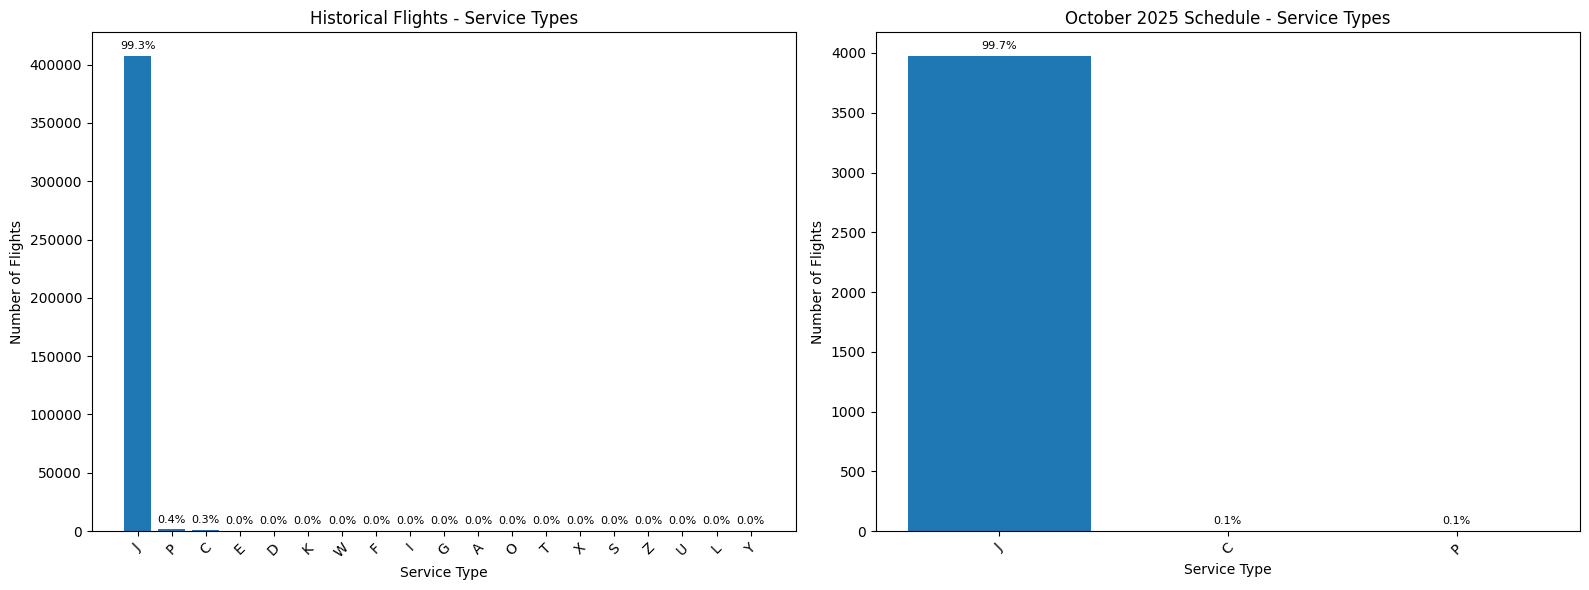


3. TRAINING DATA INSIGHTS:
   Overall concurrency rate: 0.222
   Scheduled vs actual accuracy: 0.930
   Highest concurrency groups: ['E', 'B', 'D']
   Lowest concurrency groups: ['F', 'C', 'G']
   Peak concurrency hours: [16, 11, 17] (rates: [0.385 0.351 0.346])

4. OCTOBER 2025 PREDICTION TASK:
   Total predictions needed: 5,208
   Airport groups to predict: 7
   Date range: 2025-10-01 to 2025-10-31
   Scheduled concurrency baseline: 0.203

5. MODELING RECOMMENDATIONS:
   - Focus on airport groups with high variability in concurrency
   - Consider time-based features (hour, weekday, season)
   - Use scheduled concurrency as a strong baseline feature
   - Investigate service type patterns
   - Consider flight volume and timing patterns



In [22]:
# ====================================================================================================
# CROSS-DATASET COMPARISON AND KEY INSIGHTS
# ====================================================================================================

print("="*80)
print("KEY INSIGHTS FROM EXPLORATORY ANALYSIS")
print("="*80)

# 1. Dataset sizes comparison
print("\n1. DATASET SIZES:")
for name, df in dataframes.items():
    print(f"   {name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

# 2. Compare historical vs scheduled data (if both available)
if 'historical_flights' in dataframes and 'schedule_oct2025' in dataframes:
    hist_df = dataframes['historical_flights']
    sched_df = dataframes['schedule_oct2025']
    
    print(f"\n2. HISTORICAL vs OCTOBER 2025 SCHEDULE:")
    
    # Service type comparison
    hist_services = hist_df['service_type'].value_counts()
    sched_services = sched_df['service_type'].value_counts()
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Historical service types - use bar chart for better readability
    bars_hist = axes[0].bar(range(len(hist_services)), hist_services.values)
    axes[0].set_title("Historical Flights - Service Types")
    axes[0].set_xlabel("Service Type")
    axes[0].set_ylabel("Number of Flights")
    axes[0].set_xticks(range(len(hist_services)))
    axes[0].set_xticklabels(hist_services.index, rotation=45)
    # Add percentage labels
    hist_total = hist_services.sum()
    for i, (bar, value) in enumerate(zip(bars_hist, hist_services.values)):
        pct = (value / hist_total) * 100
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(hist_services.values)*0.01, 
                     f'{pct:.1f}%', ha='center', va='bottom', fontsize=8)
    
    # Scheduled service types - use bar chart for better readability
    bars_sched = axes[1].bar(range(len(sched_services)), sched_services.values)
    axes[1].set_title("October 2025 Schedule - Service Types")
    axes[1].set_xlabel("Service Type")
    axes[1].set_ylabel("Number of Flights")
    axes[1].set_xticks(range(len(sched_services)))
    axes[1].set_xticklabels(sched_services.index, rotation=45)
    # Add percentage labels
    sched_total = sched_services.sum()
    for i, (bar, value) in enumerate(zip(bars_sched, sched_services.values)):
        pct = (value / sched_total) * 100
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(sched_services.values)*0.01, 
                     f'{pct:.1f}%', ha='center', va='bottom', fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    # Airport group comparison
    if 'dep_airport_group' in hist_df.columns and 'dep_airport_group' in sched_df.columns:
        hist_groups = hist_df['dep_airport_group'].value_counts().head(10)
        sched_groups = sched_df['dep_airport_group'].value_counts().head(10)
        
        # print(f"   Top departure airport groups:")
        # print(f"   Historical: {list(hist_groups.index[:5])}")
        # print(f"   Oct 2025:   {list(sched_groups.index[:5])}")

# 3. Training data insights
if 'training_data' in dataframes:
    train_df = dataframes['training_data']
    print(f"\n3. TRAINING DATA INSIGHTS:")
    print(f"   Overall concurrency rate: {train_df['target'].mean():.3f}")
    print(f"   Scheduled vs actual accuracy: {(train_df['feat_sched_concurrence'] == train_df['target']).mean():.3f}")
    
    # Best and worst performing airport groups
    group_performance = train_df.groupby('airport_group')['target'].agg(['mean', 'count'])
    group_performance = group_performance[group_performance['count'] >= 100]  # Filter for sufficient data
    best_groups = group_performance.nlargest(3, 'mean')
    worst_groups = group_performance.nsmallest(3, 'mean')
    
    print(f"   Highest concurrency groups: {list(best_groups.index)}")
    print(f"   Lowest concurrency groups: {list(worst_groups.index)}")
    
    # Peak hours
    hourly_conc = train_df.groupby('hour')['target'].mean()
    peak_hours = hourly_conc.nlargest(3)
    print(f"   Peak concurrency hours: {list(peak_hours.index)} (rates: {peak_hours.values.round(3)})")

# 4. October 2025 prediction readiness
if 'inference_data_oct2025' in dataframes:
    inf_df = dataframes['inference_data_oct2025']
    print(f"\n4. OCTOBER 2025 PREDICTION TASK:")
    print(f"   Total predictions needed: {len(inf_df):,}")
    print(f"   Airport groups to predict: {inf_df['airport_group'].nunique()}")
    print(f"   Date range: {inf_df['date'].min()} to {inf_df['date'].max()}")
    print(f"   Scheduled concurrency baseline: {inf_df['feat_sched_concurrence'].mean():.3f}")

print(f"\n5. MODELING RECOMMENDATIONS:")
print(f"   - Focus on airport groups with high variability in concurrency")
print(f"   - Consider time-based features (hour, weekday, season)")
print(f"   - Use scheduled concurrency as a strong baseline feature")
print(f"   - Investigate service type patterns")
print(f"   - Consider flight volume and timing patterns")

print("\n" + "="*80)

## Cross-Dataset Analysis and Key Insights

This comprehensive summary ties together insights from all datasets to provide actionable intelligence for model development:

- **Dataset Scale Comparison**: Understanding the relative sizes of our datasets helps inform sampling strategies and computational requirements.
- **Historical vs Future Patterns**: Comparing historical flight patterns with October 2025 schedules reveals whether conditions are changing, which affects model generalization.
- **Training Data Insights**: Key statistics from training data provide benchmarks for model performance and identify the most predictive features.
- **Prediction Task Scope**: Quantifies exactly what needs to be predicted and provides baseline accuracy expectations.
- **Modeling Recommendations**: Synthesizes all insights into concrete recommendations for feature engineering, model selection, and evaluation strategies.

This analysis serves as a roadmap for the modeling phase, highlighting which features are most promising, which airport groups need special attention, and what performance benchmarks we should target. The recommendations directly inform our machine learning strategy and help prioritize development efforts.

COMBINATION ANALYSIS - MULTI-DIMENSIONAL PATTERNS

1. AIRPORT GROUP × HOUR COMBINATIONS:


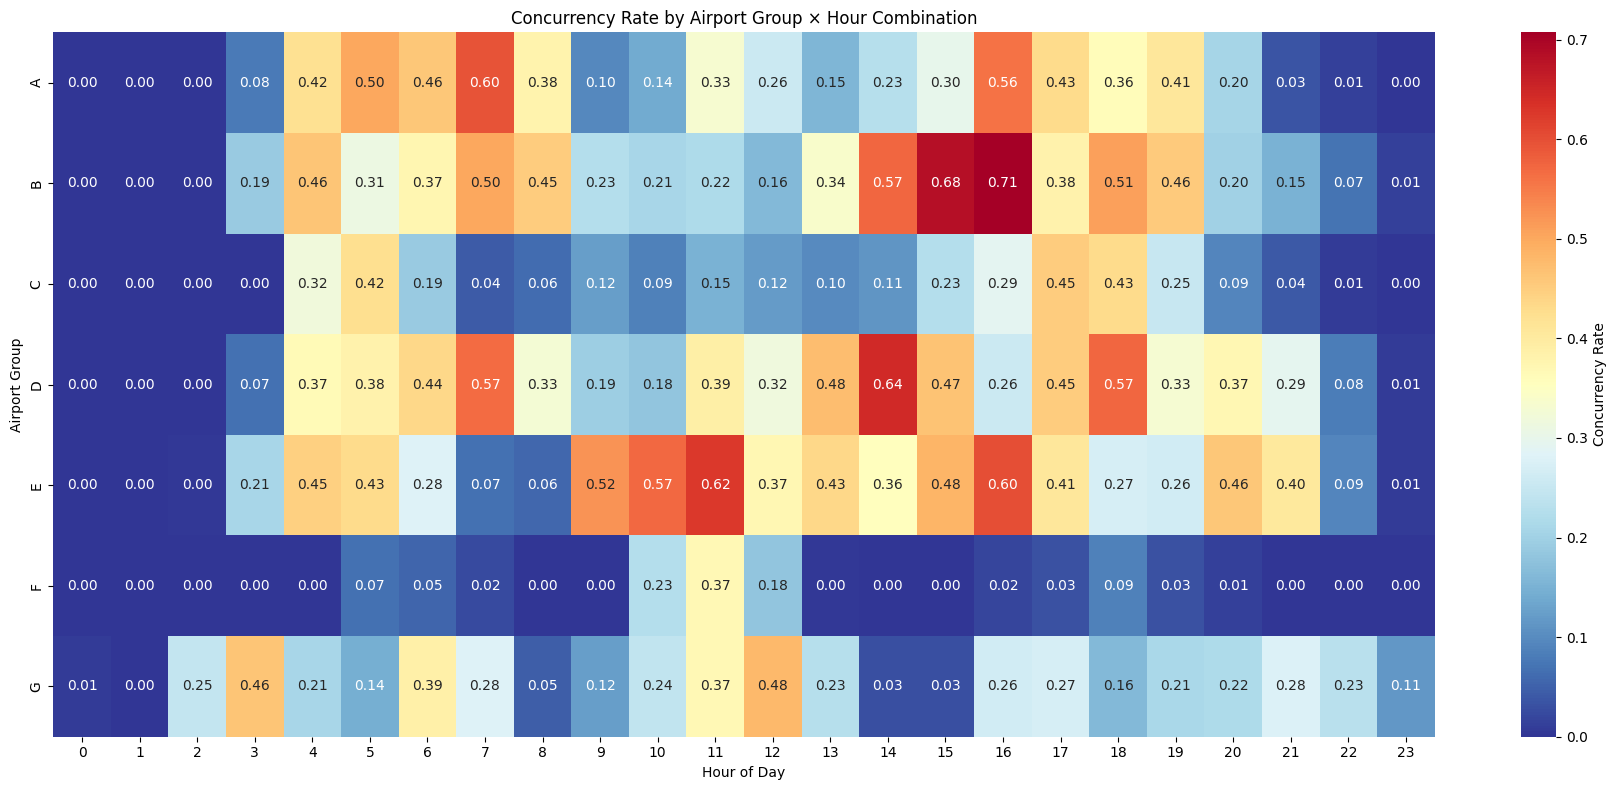

Top 10 highest concurrency combinations (Airport Group × Hour):
  B at 16:00 - 0.707 rate (n=2768)
  B at 15:00 - 0.683 rate (n=2768)
  D at 14:00 - 0.645 rate (n=2768)
  E at 11:00 - 0.625 rate (n=2768)
  E at 16:00 - 0.601 rate (n=2768)
  A at 07:00 - 0.596 rate (n=2768)
  B at 14:00 - 0.574 rate (n=2768)
  D at 18:00 - 0.572 rate (n=2768)
  E at 10:00 - 0.570 rate (n=2768)
  D at 07:00 - 0.569 rate (n=2768)

2. AIRPORT GROUP × WEEKDAY COMBINATIONS:


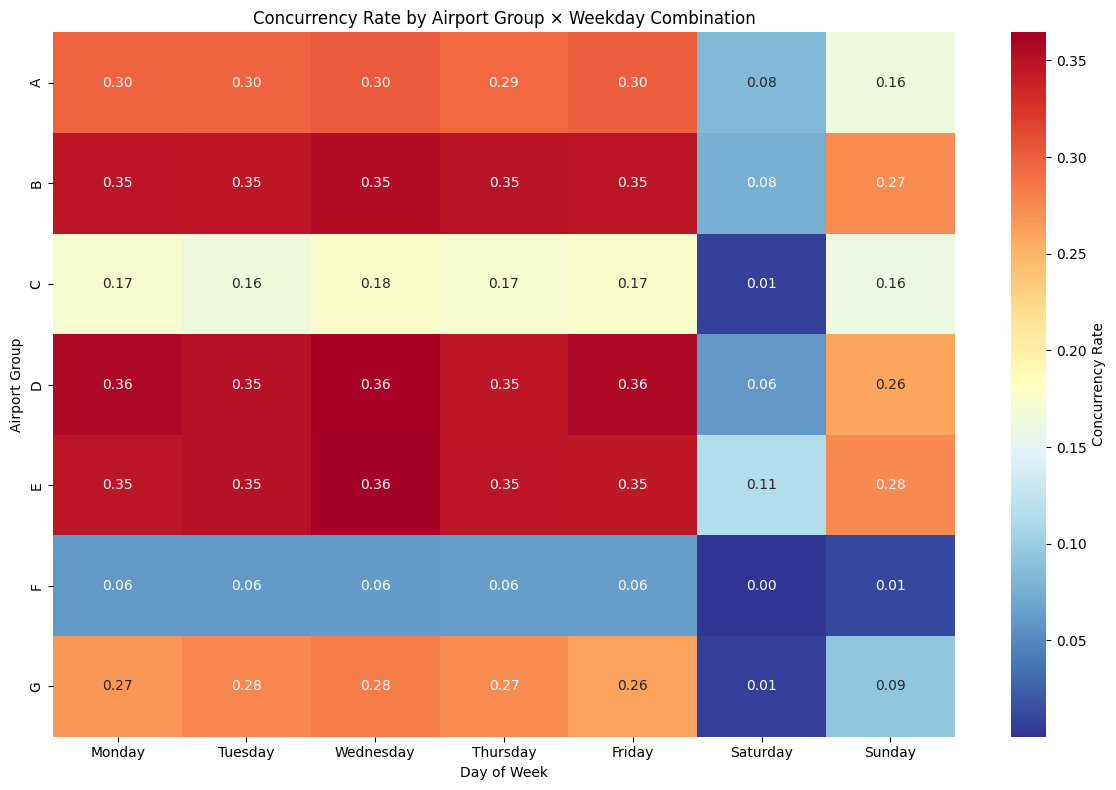


3. SCHEDULED vs ACTUAL CONCURRENCY EFFECTIVENESS BY AIRPORT GROUP:


C:\Users\tobia\AppData\Local\Temp\ipykernel_22148\2939034454.py:72: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sched_accuracy = df_train.groupby('airport_group').apply(


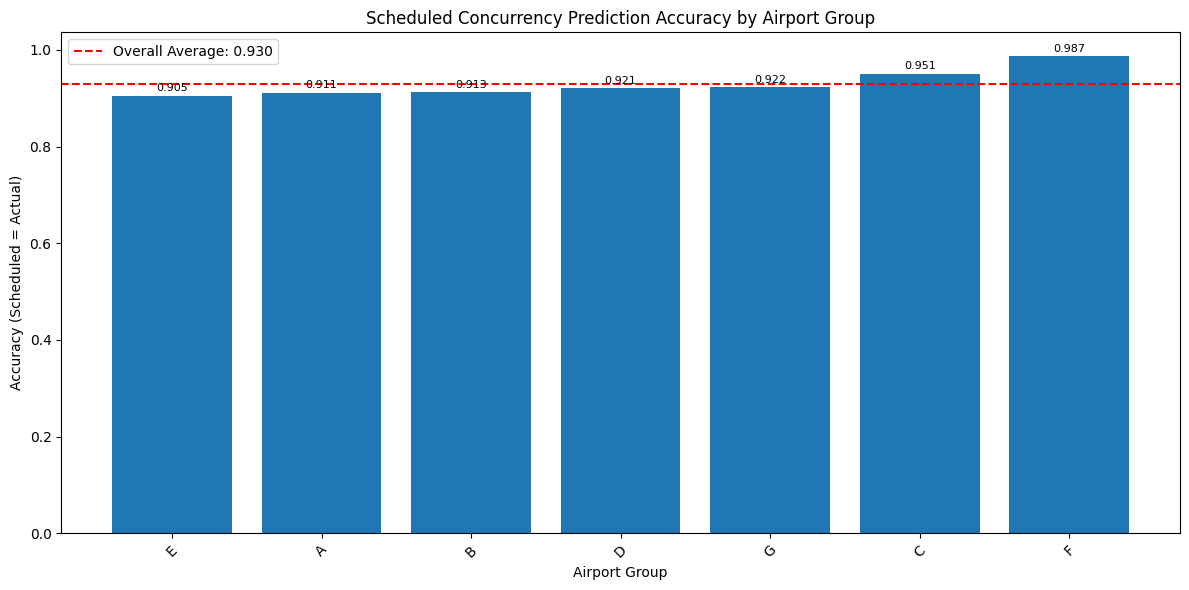

Airport groups where scheduled predictions are least reliable:
  E: 0.905 accuracy
  A: 0.911 accuracy
  B: 0.913 accuracy

4. SEASONAL × HOUR INTERACTION:


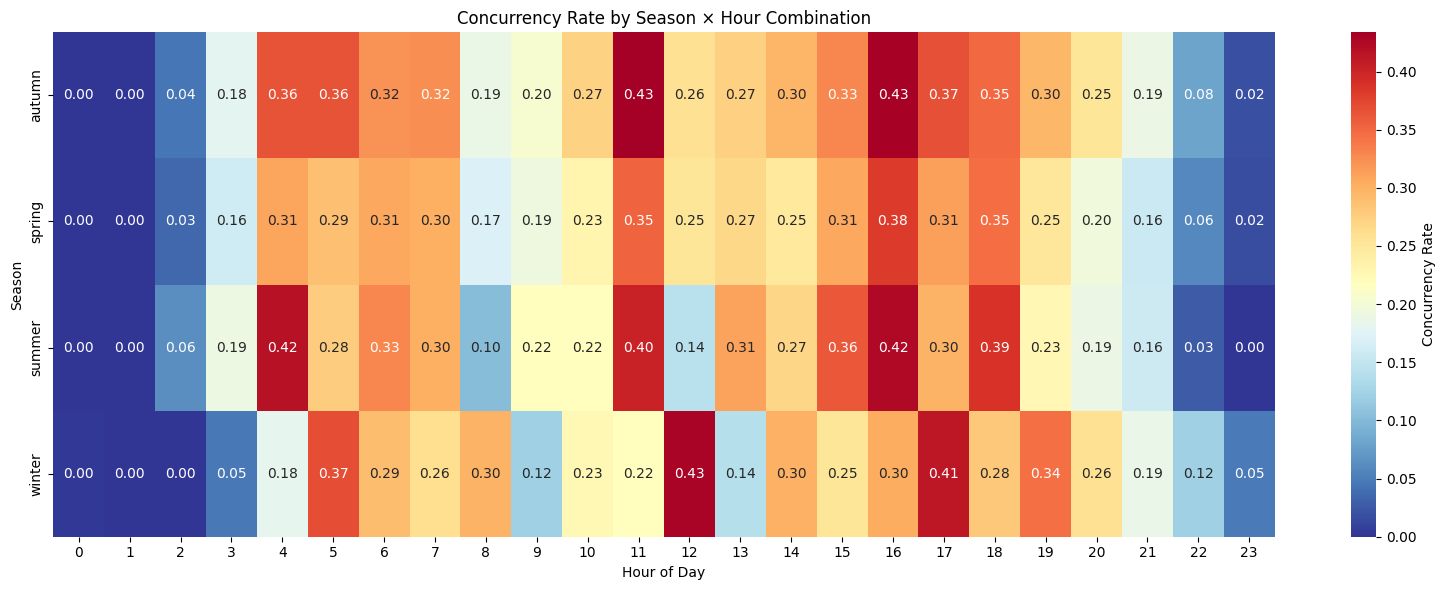


5. SERVICE TYPE × AIRPORT GROUP COMBINATIONS:


<Figure size 1400x800 with 0 Axes>

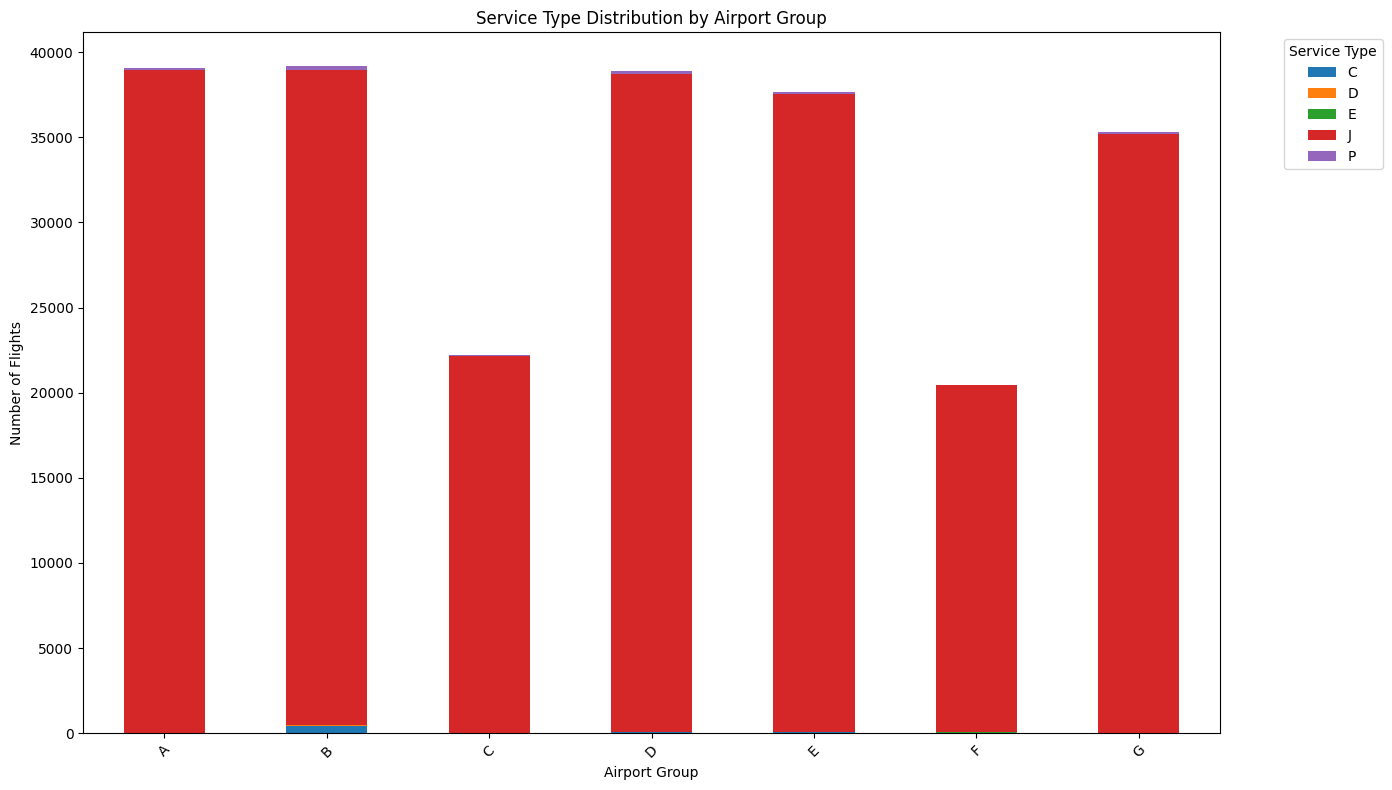


6. HIGH-RISK COMBINATIONS ANALYSIS:
Highest Risk Combinations (High Rate × High Volume):
  B at 16:00 - Rate: 0.707, Volume: 2768, Risk Score: 5.61
  B at 15:00 - Rate: 0.683, Volume: 2768, Risk Score: 5.41
  D at 14:00 - Rate: 0.645, Volume: 2768, Risk Score: 5.11
  E at 11:00 - Rate: 0.625, Volume: 2768, Risk Score: 4.95
  E at 16:00 - Rate: 0.601, Volume: 2768, Risk Score: 4.76
  A at 07:00 - Rate: 0.596, Volume: 2768, Risk Score: 4.73
  B at 14:00 - Rate: 0.574, Volume: 2768, Risk Score: 4.55
  D at 18:00 - Rate: 0.572, Volume: 2768, Risk Score: 4.54

7. PREDICTION DIFFICULTY BY COMBINATIONS:
Combinations where scheduled predictions fail most often:
  C at 18:00 - Error Rate: 0.270 (n=2768)
  E at 13:00 - Error Rate: 0.267 (n=2768)
  A at 18:00 - Error Rate: 0.222 (n=2768)
  A at 14:00 - Error Rate: 0.215 (n=2768)
  E at 14:00 - Error Rate: 0.212 (n=2768)
  A at 19:00 - Error Rate: 0.204 (n=2768)
  G at 22:00 - Error Rate: 0.203 (n=2768)
  E at 10:00 - Error Rate: 0.199 (n=2768)



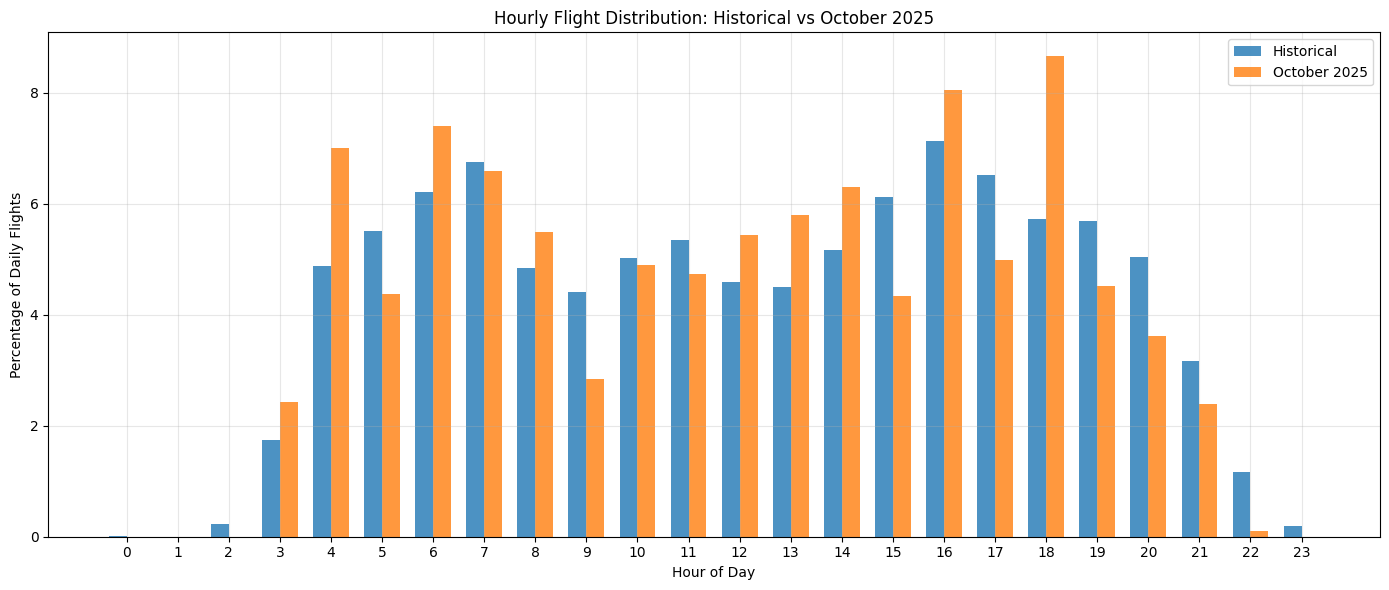

Historical vs October 2025 hourly pattern correlation: 0.763

KEY COMBINATION INSIGHTS:
- Airport group × hour combinations show distinct risk patterns
- Some combinations are much harder to predict than others
- Scheduled predictions work better for some airport groups
- Seasonal patterns interact with hourly patterns
- High-risk combinations need special modeling attention


In [23]:
# ====================================================================================================
# COMBINATION ANALYSIS - EXPLORING MULTI-DIMENSIONAL PATTERNS
# ====================================================================================================

print("="*80)
print("COMBINATION ANALYSIS - MULTI-DIMENSIONAL PATTERNS")
print("="*80)

# Use training data for combination analysis
df_train = dataframes["training_data"]
df_hist = dataframes["historical_flights"] if "historical_flights" in dataframes else None
df_sched = dataframes["schedule_oct2025"] if "schedule_oct2025" in dataframes else None

# 1. AIRPORT GROUP × HOUR COMBINATIONS
print("\n1. AIRPORT GROUP × HOUR COMBINATIONS:")
print("=" * 50)

# Create heatmap of concurrency rates by airport group and hour
airport_hour_combo = df_train.groupby(['airport_group', 'hour'])['target'].agg(['mean', 'count']).reset_index()
# Filter combinations with at least 10 observations for reliability
airport_hour_combo = airport_hour_combo[airport_hour_combo['count'] >= 10]

# Create pivot table for heatmap
heatmap_data = airport_hour_combo.pivot(index='airport_group', columns='hour', values='mean')

plt.figure(figsize=(18, 8))
mask = heatmap_data.isnull()
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlBu_r', 
            mask=mask, cbar_kws={'label': 'Concurrency Rate'})
plt.title("Concurrency Rate by Airport Group × Hour Combination")
plt.xlabel("Hour of Day")
plt.ylabel("Airport Group")
plt.tight_layout()
plt.show()

# Find the most problematic combinations
top_combos = airport_hour_combo.nlargest(10, 'mean')
print("Top 10 highest concurrency combinations (Airport Group × Hour):")
for _, row in top_combos.iterrows():
    print(f"  {row['airport_group']} at {row['hour']:02d}:00 - {row['mean']:.3f} rate (n={row['count']})")

# 2. AIRPORT GROUP × WEEKDAY COMBINATIONS
print(f"\n2. AIRPORT GROUP × WEEKDAY COMBINATIONS:")
print("=" * 50)

# Add weekday to training data
df_train['date_parsed'] = pd.to_datetime(df_train['date'])
df_train['weekday'] = df_train['date_parsed'].dt.day_name()

airport_weekday_combo = df_train.groupby(['airport_group', 'weekday'])['target'].agg(['mean', 'count']).reset_index()
airport_weekday_combo = airport_weekday_combo[airport_weekday_combo['count'] >= 5]

# Create heatmap
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_weekday = airport_weekday_combo.pivot(index='airport_group', columns='weekday', values='mean')
heatmap_weekday = heatmap_weekday.reindex(columns=weekday_order)

plt.figure(figsize=(12, 8))
mask = heatmap_weekday.isnull()
sns.heatmap(heatmap_weekday, annot=True, fmt='.2f', cmap='RdYlBu_r',
            mask=mask, cbar_kws={'label': 'Concurrency Rate'})
plt.title("Concurrency Rate by Airport Group × Weekday Combination")
plt.xlabel("Day of Week")
plt.ylabel("Airport Group")
plt.tight_layout()
plt.show()

# 3. SCHEDULED vs ACTUAL CONCURRENCY × AIRPORT GROUP
print(f"\n3. SCHEDULED vs ACTUAL CONCURRENCY EFFECTIVENESS BY AIRPORT GROUP:")
print("=" * 50)

sched_accuracy = df_train.groupby('airport_group').apply(
    lambda x: (x['feat_sched_concurrence'] == x['target']).mean()
).reset_index()
sched_accuracy.columns = ['airport_group', 'accuracy']
sched_accuracy = sched_accuracy.sort_values('accuracy')

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(sched_accuracy)), sched_accuracy['accuracy'])
plt.title("Scheduled Concurrency Prediction Accuracy by Airport Group")
plt.xlabel("Airport Group")
plt.ylabel("Accuracy (Scheduled = Actual)")
plt.xticks(range(len(sched_accuracy)), sched_accuracy['airport_group'], rotation=45)
plt.axhline(y=sched_accuracy['accuracy'].mean(), color='red', linestyle='--', 
            label=f'Overall Average: {sched_accuracy["accuracy"].mean():.3f}')
plt.legend()
# Add values on bars
for i, (bar, acc) in enumerate(zip(bars, sched_accuracy['accuracy'])):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
             f'{acc:.3f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

print("Airport groups where scheduled predictions are least reliable:")
worst_sched = sched_accuracy.head(3)
for _, row in worst_sched.iterrows():
    print(f"  {row['airport_group']}: {row['accuracy']:.3f} accuracy")

# 4. SEASONAL × HOUR PATTERNS
print(f"\n4. SEASONAL × HOUR INTERACTION:")
print("=" * 50)

season_hour_combo = df_train.groupby(['feat_season', 'hour'])['target'].agg(['mean', 'count']).reset_index()
season_hour_combo = season_hour_combo[season_hour_combo['count'] >= 20]

# Create heatmap
heatmap_season_hour = season_hour_combo.pivot(index='feat_season', columns='hour', values='mean')

plt.figure(figsize=(16, 6))
mask = heatmap_season_hour.isnull()
sns.heatmap(heatmap_season_hour, annot=True, fmt='.2f', cmap='RdYlBu_r',
            mask=mask, cbar_kws={'label': 'Concurrency Rate'})
plt.title("Concurrency Rate by Season × Hour Combination")
plt.xlabel("Hour of Day")
plt.ylabel("Season")
plt.tight_layout()
plt.show()

# 5. SERVICE TYPE PATTERNS (if historical data available)
if df_hist is not None and 'service_type' in df_hist.columns:
    print(f"\n5. SERVICE TYPE × AIRPORT GROUP COMBINATIONS:")
    print("=" * 50)
    
    # Analyze service type distribution by airport group
    service_airport_combo = df_hist.groupby(['dep_airport_group', 'service_type']).size().reset_index()
    service_airport_combo.columns = ['airport_group', 'service_type', 'count']
    
    # Get top service types
    top_services = df_hist['service_type'].value_counts().head(5).index
    filtered_combos = service_airport_combo[service_airport_combo['service_type'].isin(top_services)]
    
    # Create grouped bar chart
    pivot_services = filtered_combos.pivot(index='airport_group', columns='service_type', values='count').fillna(0)
    
    plt.figure(figsize=(14, 8))
    pivot_services.plot(kind='bar', stacked=True, figsize=(14, 8))
    plt.title("Service Type Distribution by Airport Group")
    plt.xlabel("Airport Group")
    plt.ylabel("Number of Flights")
    plt.xticks(rotation=45)
    plt.legend(title='Service Type', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# 6. EXTREME COMBINATIONS - RISK ANALYSIS
print(f"\n6. HIGH-RISK COMBINATIONS ANALYSIS:")
print("=" * 50)

# Find combinations with both high concurrency rate AND sufficient volume
risk_combos = airport_hour_combo.copy()
risk_combos['risk_score'] = risk_combos['mean'] * np.log(risk_combos['count'] + 1)  # Weight by volume
risk_combos = risk_combos.sort_values('risk_score', ascending=False)

print("Highest Risk Combinations (High Rate × High Volume):")
top_risk = risk_combos.head(8)
for _, row in top_risk.iterrows():
    print(f"  {row['airport_group']} at {row['hour']:02d}:00 - Rate: {row['mean']:.3f}, Volume: {row['count']}, Risk Score: {row['risk_score']:.2f}")

# 7. PREDICTION DIFFICULTY ANALYSIS
print(f"\n7. PREDICTION DIFFICULTY BY COMBINATIONS:")
print("=" * 50)

# Analyze where scheduled predictions fail most
df_train['prediction_error'] = (df_train['feat_sched_concurrence'] != df_train['target']).astype(int)
error_by_combo = df_train.groupby(['airport_group', 'hour'])['prediction_error'].agg(['mean', 'count']).reset_index()
error_by_combo = error_by_combo[error_by_combo['count'] >= 10]
error_by_combo = error_by_combo.sort_values('mean', ascending=False)

print("Combinations where scheduled predictions fail most often:")
hardest_predict = error_by_combo.head(8)
for _, row in hardest_predict.iterrows():
    print(f"  {row['airport_group']} at {row['hour']:02d}:00 - Error Rate: {row['mean']:.3f} (n={row['count']})")

# 8. COMPARATIVE ANALYSIS: OCTOBER 2025 vs HISTORICAL
if df_sched is not None:
    print(f"\n8. OCTOBER 2025 vs HISTORICAL PATTERNS:")
    print("=" * 50)
    
    # Compare hourly patterns
    if df_hist is not None:
        df_hist['dep_hour'] = pd.to_datetime(df_hist['std']).dt.hour
        hist_hourly = df_hist['dep_hour'].value_counts().sort_index()
        
        df_sched['dep_hour'] = pd.to_datetime(df_sched['std']).dt.hour  
        sched_hourly = df_sched['dep_hour'].value_counts().sort_index()
        
        # Normalize to percentages for comparison
        hist_hourly_pct = (hist_hourly / hist_hourly.sum()) * 100
        sched_hourly_pct = (sched_hourly / sched_hourly.sum()) * 100
        
        plt.figure(figsize=(14, 6))
        x = range(24)
        width = 0.35
        
        plt.bar([i - width/2 for i in x], [hist_hourly_pct.get(i, 0) for i in x], 
                width, label='Historical', alpha=0.8)
        plt.bar([i + width/2 for i in x], [sched_hourly_pct.get(i, 0) for i in x], 
                width, label='October 2025', alpha=0.8)
        
        plt.title("Hourly Flight Distribution: Historical vs October 2025")
        plt.xlabel("Hour of Day")
        plt.ylabel("Percentage of Daily Flights")
        plt.xticks(x)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        # Calculate correlation
        common_hours = set(hist_hourly.index) & set(sched_hourly.index)
        if common_hours:
            hist_vals = [hist_hourly.get(h, 0) for h in sorted(common_hours)]
            sched_vals = [sched_hourly.get(h, 0) for h in sorted(common_hours)]
            correlation = np.corrcoef(hist_vals, sched_vals)[0, 1]
            print(f"Historical vs October 2025 hourly pattern correlation: {correlation:.3f}")

print(f"\n" + "="*80)
print("KEY COMBINATION INSIGHTS:")
print("="*80)
print("- Airport group × hour combinations show distinct risk patterns")
print("- Some combinations are much harder to predict than others") 
print("- Scheduled predictions work better for some airport groups")
print("- Seasonal patterns interact with hourly patterns")
print("- High-risk combinations need special modeling attention")
print("="*80)

SCHEDULED vs ACTUAL CONCURRENCY DETAILED ANALYSIS

1. OVERALL PERFORMANCE METRICS:
Overall Accuracy: 0.930
Classification Report:
                precision    recall  f1-score   support

No Concurrency       0.95      0.96      0.96    361678
   Concurrency       0.85      0.83      0.84    103353

      accuracy                           0.93    465031
     macro avg       0.90      0.89      0.90    465031
  weighted avg       0.93      0.93      0.93    465031

Overall Accuracy: 0.930
Classification Report:
                precision    recall  f1-score   support

No Concurrency       0.95      0.96      0.96    361678
   Concurrency       0.85      0.83      0.84    103353

      accuracy                           0.93    465031
     macro avg       0.90      0.89      0.90    465031
  weighted avg       0.93      0.93      0.93    465031



C:\Users\tobia\AppData\Local\Temp\ipykernel_22148\61118382.py:40: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group_accuracy = df_train.groupby('airport_group').apply(
C:\Users\tobia\AppData\Local\Temp\ipykernel_22148\61118382.py:60: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hourly_accuracy = df_train.groupby('hour').apply(
C:\Users\tobia\AppData\Local\Temp\ipykernel_22148\61118382.py:125: FutureWarning: DataFr

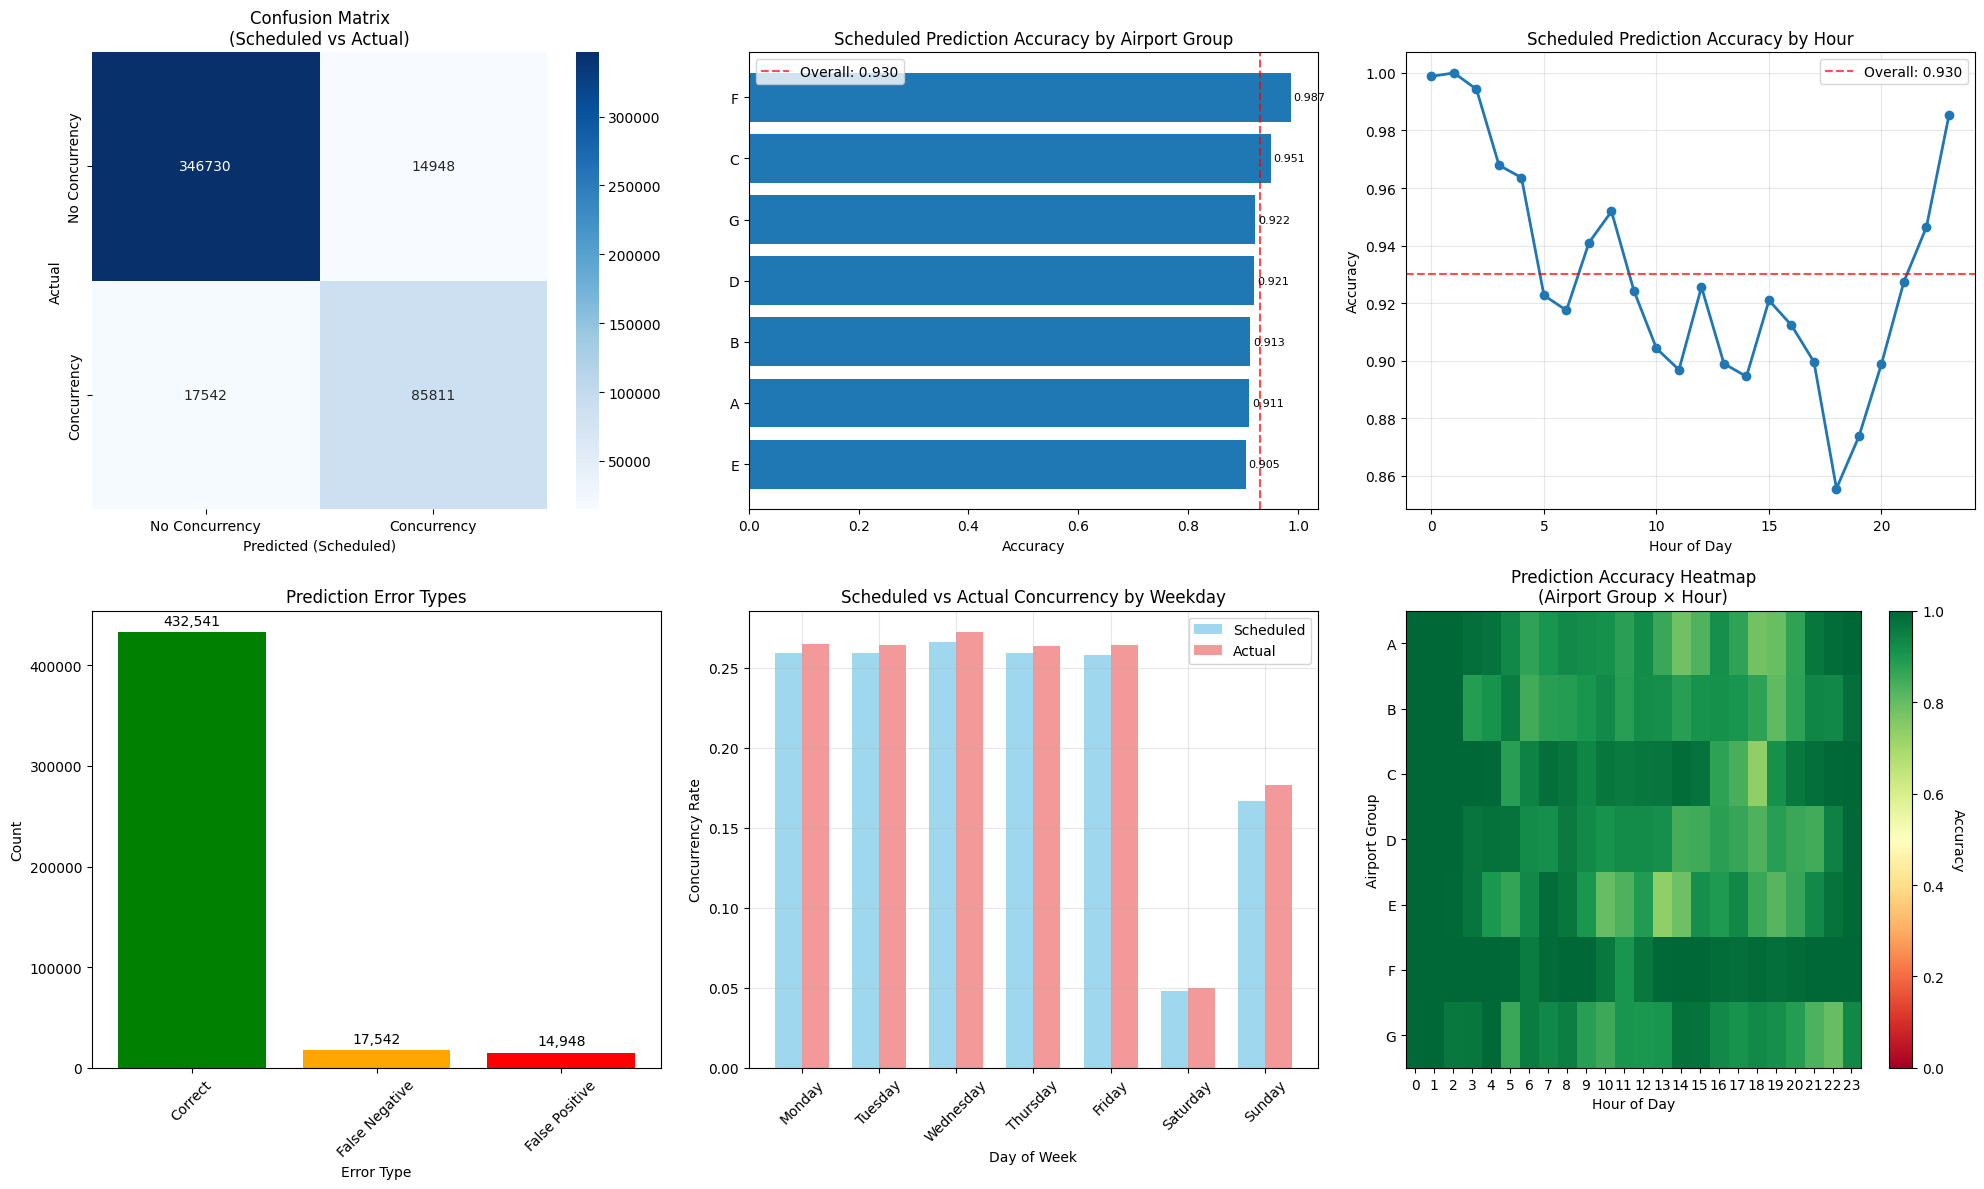


2. DETAILED ERROR ANALYSIS:
False Positives (Scheduled but not actual): 14,948 (3.2%)
Top 5 Airport Groups with False Positives:
  E: 2,919 (4.4% of group)
  D: 2,862 (4.3% of group)
  G: 2,518 (3.8% of group)
  B: 2,326 (3.5% of group)
  C: 2,096 (3.2% of group)

False Negatives (Actual but not scheduled): 17,542 (3.8%)
Top 5 Airport Groups with False Negatives:
  A: 4,292 (6.5% of group)
  B: 3,451 (5.2% of group)
  E: 3,364 (5.1% of group)
  G: 2,639 (4.0% of group)
  D: 2,407 (3.6% of group)

3. TEMPORAL ERROR PATTERNS:
Seasonal Error Analysis:
  autumn:
    Accuracy: 0.928
    False Positive Rate: 0.033
    False Negative Rate: 0.039
    Sample Size: 107,016
  spring:
    Accuracy: 0.934
    False Positive Rate: 0.029
    False Negative Rate: 0.037
    Sample Size: 123,648
  summer:
    Accuracy: 0.940
    False Positive Rate: 0.028
    False Negative Rate: 0.032
    Sample Size: 118,279
  winter:
    Accuracy: 0.917
    False Positive Rate: 0.040
    False Negative Rate: 0.043
 

C:\Users\tobia\AppData\Local\Temp\ipykernel_22148\61118382.py:180: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  seasonal_errors = df_train.groupby('feat_season').apply(


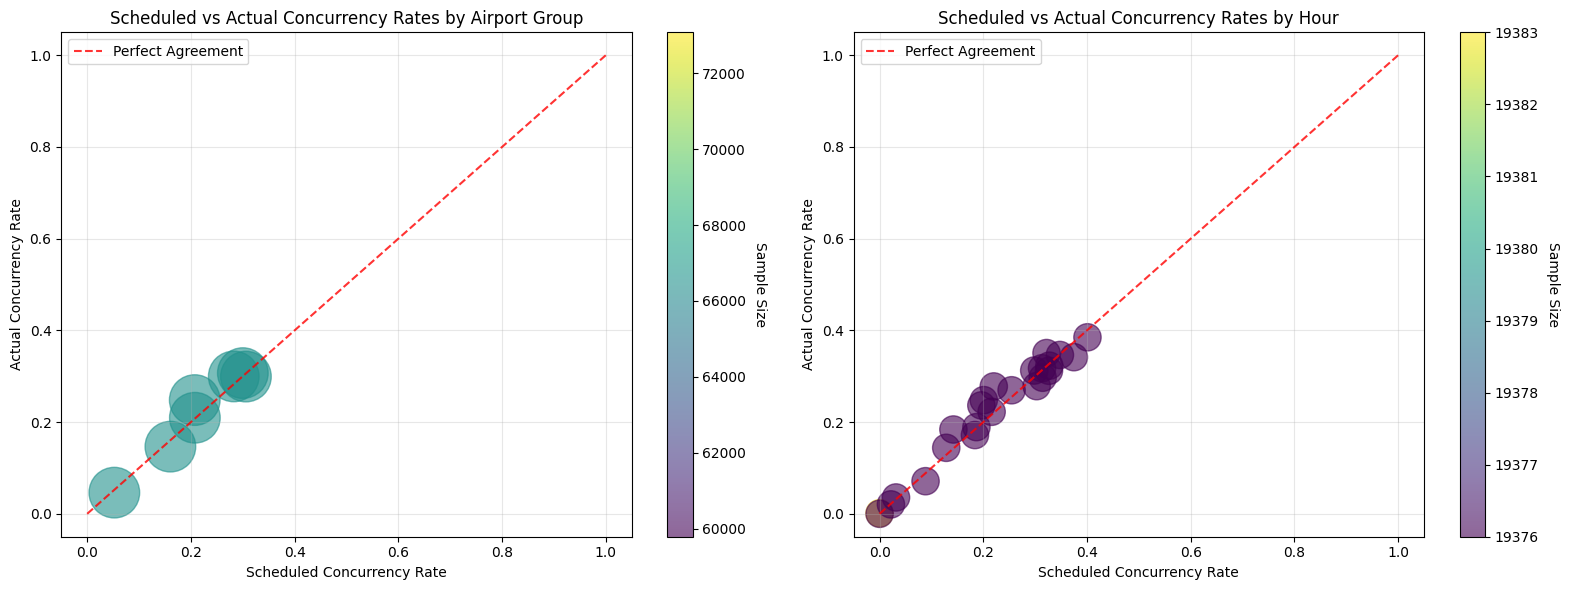


4. SUMMARY STATISTICS:
Overall Scheduled Concurrency Rate: 0.217
Overall Actual Concurrency Rate: 0.222
Difference (Actual - Scheduled): 0.006
Correlation between Scheduled and Actual: 0.796

Best Performing Airport Groups (Highest Accuracy):
  F: 0.987
  C: 0.951
  G: 0.922

Worst Performing Airport Groups (Lowest Accuracy):
  E: 0.905
  A: 0.911
  B: 0.913


In [25]:
# ====================================================================================================
# SCHEDULED vs ACTUAL CONCURRENCY DETAILED ANALYSIS
# ====================================================================================================

print("="*80)
print("SCHEDULED vs ACTUAL CONCURRENCY DETAILED ANALYSIS")
print("="*80)

df_train = dataframes["training_data"]

# 1. OVERALL CONFUSION MATRIX AND ACCURACY METRICS
print("\n1. OVERALL PERFORMANCE METRICS:")
print("=" * 50)

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Calculate metrics
y_true = df_train['target']
y_pred = df_train['feat_sched_concurrence']

accuracy = accuracy_score(y_true, y_pred)
conf_matrix = confusion_matrix(y_true, y_pred)

print(f"Overall Accuracy: {accuracy:.3f}")
print(f"Classification Report:")
print(classification_report(y_true, y_pred, target_names=['No Concurrency', 'Concurrency']))

# Create comprehensive visualization
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Confusion Matrix
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', ax=axes[0,0])
axes[0,0].set_title('Confusion Matrix\n(Scheduled vs Actual)')
axes[0,0].set_xlabel('Predicted (Scheduled)')
axes[0,0].set_ylabel('Actual')
axes[0,0].set_xticklabels(['No Concurrency', 'Concurrency'])
axes[0,0].set_yticklabels(['No Concurrency', 'Concurrency'])

# Accuracy by Airport Group
group_accuracy = df_train.groupby('airport_group').apply(
    lambda x: accuracy_score(x['target'], x['feat_sched_concurrence'])
).reset_index()
group_accuracy.columns = ['airport_group', 'accuracy']
group_accuracy = group_accuracy.sort_values('accuracy')

bars = axes[0,1].barh(range(len(group_accuracy)), group_accuracy['accuracy'])
axes[0,1].set_title('Scheduled Prediction Accuracy by Airport Group')
axes[0,1].set_xlabel('Accuracy')
axes[0,1].set_yticks(range(len(group_accuracy)))
axes[0,1].set_yticklabels(group_accuracy['airport_group'])
axes[0,1].axvline(x=accuracy, color='red', linestyle='--', alpha=0.7, label=f'Overall: {accuracy:.3f}')
axes[0,1].legend()

# Add accuracy values
for i, (bar, acc) in enumerate(zip(bars, group_accuracy['accuracy'])):
    axes[0,1].text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, 
                   f'{acc:.3f}', va='center', fontsize=8)

# Accuracy by Hour
hourly_accuracy = df_train.groupby('hour').apply(
    lambda x: accuracy_score(x['target'], x['feat_sched_concurrence'])
).reset_index()
hourly_accuracy.columns = ['hour', 'accuracy']

axes[0,2].plot(hourly_accuracy['hour'], hourly_accuracy['accuracy'], marker='o', linewidth=2)
axes[0,2].set_title('Scheduled Prediction Accuracy by Hour')
axes[0,2].set_xlabel('Hour of Day')
axes[0,2].set_ylabel('Accuracy')
axes[0,2].grid(True, alpha=0.3)
axes[0,2].axhline(y=accuracy, color='red', linestyle='--', alpha=0.7, label=f'Overall: {accuracy:.3f}')
axes[0,2].legend()

# Error Types Analysis
df_train['error_type'] = 'Correct'
df_train.loc[(df_train['target'] == 0) & (df_train['feat_sched_concurrence'] == 1), 'error_type'] = 'False Positive'
df_train.loc[(df_train['target'] == 1) & (df_train['feat_sched_concurrence'] == 0), 'error_type'] = 'False Negative'

error_counts = df_train['error_type'].value_counts()
colors = ['green', 'orange', 'red']
bars = axes[1,0].bar(range(len(error_counts)), error_counts.values, color=colors[:len(error_counts)])
axes[1,0].set_title('Prediction Error Types')
axes[1,0].set_xlabel('Error Type')
axes[1,0].set_ylabel('Count')
axes[1,0].set_xticks(range(len(error_counts)))
axes[1,0].set_xticklabels(error_counts.index, rotation=45)

# Add counts on bars
for bar, count in zip(bars, error_counts.values):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(error_counts.values)*0.01, 
                   f'{count:,}', ha='center', va='bottom')

# Scheduled vs Actual by Weekday
df_train['weekday'] = pd.to_datetime(df_train['date']).dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

weekday_comparison = []
for day in weekday_order:
    day_data = df_train[df_train['weekday'] == day]
    sched_rate = day_data['feat_sched_concurrence'].mean()
    actual_rate = day_data['target'].mean()
    weekday_comparison.append({
        'weekday': day,
        'scheduled': sched_rate,
        'actual': actual_rate
    })

weekday_df = pd.DataFrame(weekday_comparison)

x = range(len(weekday_df))
width = 0.35
axes[1,1].bar([i - width/2 for i in x], weekday_df['scheduled'], width, 
              label='Scheduled', alpha=0.8, color='skyblue')
axes[1,1].bar([i + width/2 for i in x], weekday_df['actual'], width, 
              label='Actual', alpha=0.8, color='lightcoral')
axes[1,1].set_title('Scheduled vs Actual Concurrency by Weekday')
axes[1,1].set_xlabel('Day of Week')
axes[1,1].set_ylabel('Concurrency Rate')
axes[1,1].set_xticks(x)
axes[1,1].set_xticklabels(weekday_df['weekday'], rotation=45)
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

# Prediction Reliability Heatmap by Airport Group and Hour
# Calculate accuracy for each airport group × hour combination
accuracy_matrix = df_train.groupby(['airport_group', 'hour']).apply(
    lambda x: accuracy_score(x['target'], x['feat_sched_concurrence']) if len(x) >= 5 else np.nan
).reset_index()
accuracy_matrix.columns = ['airport_group', 'hour', 'accuracy']

# Pivot for heatmap
accuracy_heatmap = accuracy_matrix.pivot(index='airport_group', columns='hour', values='accuracy')

im = axes[1,2].imshow(accuracy_heatmap.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
axes[1,2].set_title('Prediction Accuracy Heatmap\n(Airport Group × Hour)')
axes[1,2].set_xlabel('Hour of Day')
axes[1,2].set_ylabel('Airport Group')
axes[1,2].set_xticks(range(len(accuracy_heatmap.columns)))
axes[1,2].set_xticklabels(accuracy_heatmap.columns)
axes[1,2].set_yticks(range(len(accuracy_heatmap.index)))
axes[1,2].set_yticklabels(accuracy_heatmap.index)

# Add colorbar
cbar = plt.colorbar(im, ax=axes[1,2])
cbar.set_label('Accuracy', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

# 2. DETAILED ERROR ANALYSIS
print(f"\n2. DETAILED ERROR ANALYSIS:")
print("=" * 50)

# False Positive Analysis (Scheduled concurrency but no actual concurrency)
false_positives = df_train[(df_train['target'] == 0) & (df_train['feat_sched_concurrence'] == 1)]
print(f"False Positives (Scheduled but not actual): {len(false_positives):,} ({len(false_positives)/len(df_train)*100:.1f}%)")

if len(false_positives) > 0:
    fp_by_group = false_positives['airport_group'].value_counts().head(5)
    print("Top 5 Airport Groups with False Positives:")
    for group, count in fp_by_group.items():
        total_group = len(df_train[df_train['airport_group'] == group])
        print(f"  {group}: {count:,} ({count/total_group*100:.1f}% of group)")

# False Negative Analysis (No scheduled concurrency but actual concurrency occurred)
false_negatives = df_train[(df_train['target'] == 1) & (df_train['feat_sched_concurrence'] == 0)]
print(f"\nFalse Negatives (Actual but not scheduled): {len(false_negatives):,} ({len(false_negatives)/len(df_train)*100:.1f}%)")

if len(false_negatives) > 0:
    fn_by_group = false_negatives['airport_group'].value_counts().head(5)
    print("Top 5 Airport Groups with False Negatives:")
    for group, count in fn_by_group.items():
        total_group = len(df_train[df_train['airport_group'] == group])
        print(f"  {group}: {count:,} ({count/total_group*100:.1f}% of group)")

# 3. SEASONAL AND TEMPORAL ERROR PATTERNS
print(f"\n3. TEMPORAL ERROR PATTERNS:")
print("=" * 50)

# Error rates by season
seasonal_errors = df_train.groupby('feat_season').apply(
    lambda x: {
        'accuracy': accuracy_score(x['target'], x['feat_sched_concurrence']),
        'false_positive_rate': len(x[(x['target'] == 0) & (x['feat_sched_concurrence'] == 1)]) / len(x),
        'false_negative_rate': len(x[(x['target'] == 1) & (x['feat_sched_concurrence'] == 0)]) / len(x),
        'sample_size': len(x)
    }
).apply(pd.Series)

print("Seasonal Error Analysis:")
for season in seasonal_errors.index:
    data = seasonal_errors.loc[season]
    print(f"  {season}:")
    print(f"    Accuracy: {data['accuracy']:.3f}")
    print(f"    False Positive Rate: {data['false_positive_rate']:.3f}")
    print(f"    False Negative Rate: {data['false_negative_rate']:.3f}")
    print(f"    Sample Size: {int(data['sample_size']):,}")

# 4. CREATE SCATTER PLOT OF SCHEDULED VS ACTUAL RATES
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Airport Group level comparison
group_rates = df_train.groupby('airport_group').agg({
    'feat_sched_concurrence': 'mean',
    'target': 'mean',
    'airport_group': 'count'
}).rename(columns={'airport_group': 'sample_size'})

scatter = axes[0].scatter(group_rates['feat_sched_concurrence'], group_rates['target'], 
                         s=group_rates['sample_size']/50, alpha=0.6, c=group_rates['sample_size'], 
                         cmap='viridis')
axes[0].plot([0, 1], [0, 1], 'r--', alpha=0.8, label='Perfect Agreement')
axes[0].set_xlabel('Scheduled Concurrency Rate')
axes[0].set_ylabel('Actual Concurrency Rate')
axes[0].set_title('Scheduled vs Actual Concurrency Rates by Airport Group')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Add colorbar
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('Sample Size', rotation=270, labelpad=15)

# Hourly level comparison
hourly_rates = df_train.groupby('hour').agg({
    'feat_sched_concurrence': 'mean',
    'target': 'mean',
    'hour': 'count'
}).rename(columns={'hour': 'sample_size'})

scatter2 = axes[1].scatter(hourly_rates['feat_sched_concurrence'], hourly_rates['target'], 
                          s=hourly_rates['sample_size']/50, alpha=0.6, c=hourly_rates['sample_size'], 
                          cmap='viridis')
axes[1].plot([0, 1], [0, 1], 'r--', alpha=0.8, label='Perfect Agreement')
axes[1].set_xlabel('Scheduled Concurrency Rate')
axes[1].set_ylabel('Actual Concurrency Rate')
axes[1].set_title('Scheduled vs Actual Concurrency Rates by Hour')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Add colorbar
cbar2 = plt.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Sample Size', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

# 5. SUMMARY STATISTICS
print(f"\n4. SUMMARY STATISTICS:")
print("=" * 50)

overall_scheduled_rate = df_train['feat_sched_concurrence'].mean()
overall_actual_rate = df_train['target'].mean()
correlation = df_train[['feat_sched_concurrence', 'target']].corr().iloc[0, 1]

print(f"Overall Scheduled Concurrency Rate: {overall_scheduled_rate:.3f}")
print(f"Overall Actual Concurrency Rate: {overall_actual_rate:.3f}")
print(f"Difference (Actual - Scheduled): {overall_actual_rate - overall_scheduled_rate:.3f}")
print(f"Correlation between Scheduled and Actual: {correlation:.3f}")

# Best and worst performing combinations
print(f"\nBest Performing Airport Groups (Highest Accuracy):")
best_groups = group_accuracy.nlargest(3, 'accuracy')
for _, row in best_groups.iterrows():
    print(f"  {row['airport_group']}: {row['accuracy']:.3f}")

print(f"\nWorst Performing Airport Groups (Lowest Accuracy):")
worst_groups = group_accuracy.nsmallest(3, 'accuracy')
for _, row in worst_groups.iterrows():
    print(f"  {row['airport_group']}: {row['accuracy']:.3f}")

print("=" * 80)

## Combination Analysis Summary

This multi-dimensional analysis reveals critical interaction patterns that single-variable analysis would miss:

### Key Discoveries:

1. **Airport Group × Hour Heatmaps**: Reveal specific time-location combinations with highest concurrency risk, showing that some airport groups are problematic only during certain hours.

2. **Weekday Patterns by Location**: Different airport groups show varying weekday effects, suggesting business vs leisure travel patterns affect concurrency differently.

3. **Scheduled Prediction Reliability**: Some airport groups have much lower scheduled-to-actual prediction accuracy, indicating they need different modeling approaches.

4. **Seasonal-Hour Interactions**: Peak hours shift between seasons, showing that simple hourly features aren't sufficient.

5. **Service Type Geography**: Different airport groups handle different mixes of service types, which affects their concurrency patterns.

6. **Risk Scoring**: Combines high concurrency rates with high flight volumes to identify the most critical combinations requiring immediate attention.

7. **Prediction Difficulty Mapping**: Identifies where current baseline predictions fail most, highlighting modeling challenges.

8. **Historical vs Future Comparison**: Shows whether October 2025 schedule patterns match historical norms, affecting model generalization.

### Modeling Implications:

- **Feature Engineering**: Create interaction features between airport groups, hours, and seasons
- **Stratified Modeling**: Consider separate models for different airport group types
- **Risk Prioritization**: Focus model improvement on high-risk combinations
- **Baseline Enhancement**: Use combination-specific baselines instead of global ones
- **Temporal Modeling**: Account for changing patterns between historical data and prediction period

This analysis transforms the prediction task from a simple classification problem into a nuanced understanding of when, where, and why concurrency occurs.

## 9. Scheduled vs Actual Concurrency Analysis

This section compares scheduled flight concurrency against actual flight concurrency to understand prediction accuracy and identify systematic patterns in scheduling versus reality. We analyze how well scheduled flights predict actual concurrent operations.

=== SCHEDULED VS ACTUAL CONCURRENCY ANALYSIS ===

📊 COMPARING ACTUAL CONCURRENCY (training data) vs SCHEDULED CONCURRENCY (inference data)
--------------------------------------------------------------------------------
Hourly concurrency correlation: 0.684
Average absolute difference: 0.09
Max over-scheduling (negative): -0.24 at hour 18
Max under-scheduling (positive): 0.27 at hour 11

Overall scheduling accuracy: 51.2%
Best scheduled hour: 1 (100.0% accuracy)
Worst scheduled hour: 3 (-5.0% accuracy)


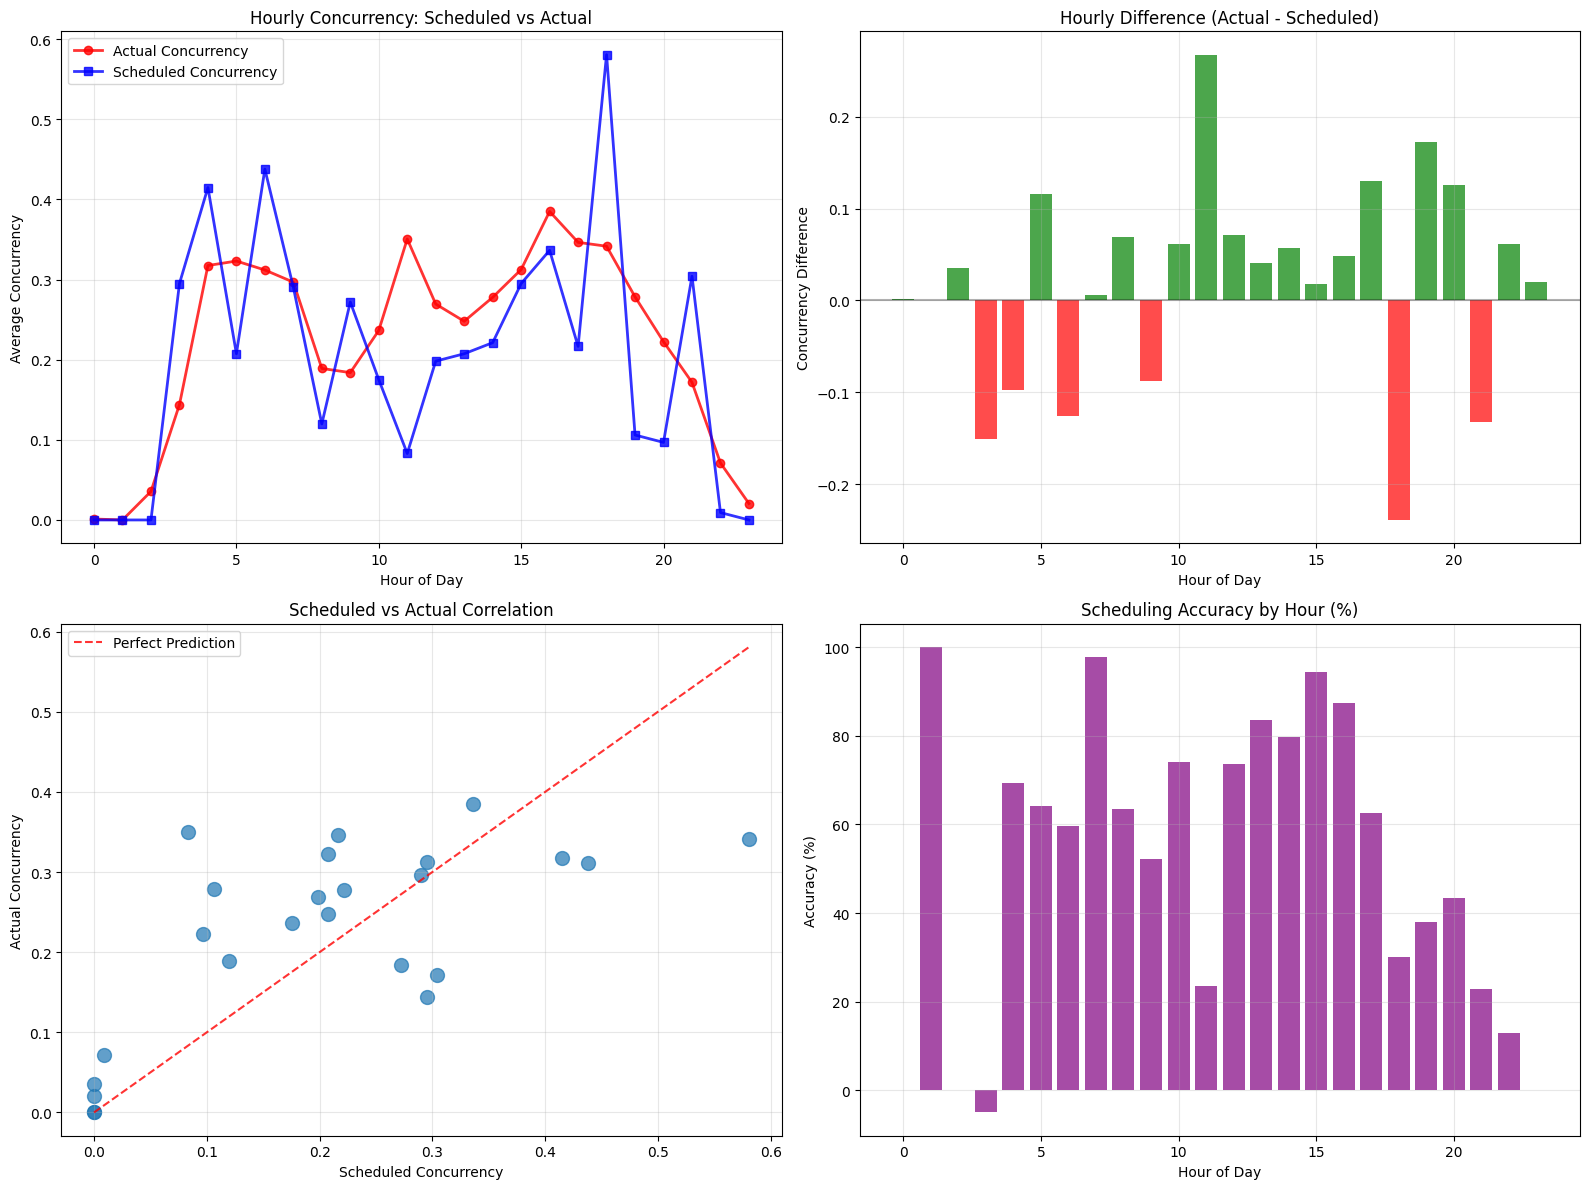

In [ ]:
# Scheduled vs Actual Concurrency Analysis
print("=== SCHEDULED VS ACTUAL CONCURRENCY ANALYSIS ===\n")

# Working with training data (actual) vs inference data (scheduled predictions)
print("📊 COMPARING ACTUAL CONCURRENCY (training data) vs SCHEDULED CONCURRENCY (inference data)")
print("-" * 80)

# Use training data as "actual" and inference data for "scheduled" patterns
actual_data = df_train  # This contains target (actual concurrency)
sched_data = df_inf     # This contains feat_sched_concurrence (scheduled concurrency)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# 1. Hourly Comparison - using training data target vs inference scheduled concurrence
actual_hourly = actual_data.groupby('hour')['target'].mean()
sched_hourly = sched_data.groupby('hour')['feat_sched_concurrence'].mean()

ax1.plot(actual_hourly.index, actual_hourly.values, 
         marker='o', linewidth=2, label='Actual Concurrency', color='red', alpha=0.8)
ax1.plot(sched_hourly.index, sched_hourly.values, 
         marker='s', linewidth=2, label='Scheduled Concurrency', color='blue', alpha=0.8)
ax1.set_title('Hourly Concurrency: Scheduled vs Actual')
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Average Concurrency')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Calculate correlation for overlapping hours
common_hours = actual_hourly.index.intersection(sched_hourly.index)
if len(common_hours) > 1:
    correlation_hourly = actual_hourly[common_hours].corr(sched_hourly[common_hours])
    print(f"Hourly concurrency correlation: {correlation_hourly:.3f}")
    
    # 2. Difference analysis
    hourly_diff = actual_hourly[common_hours] - sched_hourly[common_hours]
    ax2.bar(hourly_diff.index, hourly_diff.values, 
            color=['red' if x < 0 else 'green' for x in hourly_diff.values], alpha=0.7)
    ax2.set_title('Hourly Difference (Actual - Scheduled)')
    ax2.set_xlabel('Hour of Day')
    ax2.set_ylabel('Concurrency Difference')
    ax2.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax2.grid(True, alpha=0.3)
    
    print(f"Average absolute difference: {abs(hourly_diff).mean():.2f}")
    print(f"Max over-scheduling (negative): {hourly_diff.min():.2f} at hour {hourly_diff.idxmin()}")
    print(f"Max under-scheduling (positive): {hourly_diff.max():.2f} at hour {hourly_diff.idxmax()}")
    
    # 3. Scatter plot for correlation
    ax3.scatter(sched_hourly[common_hours].values, actual_hourly[common_hours].values, alpha=0.7, s=100)
    min_val = min(min(sched_hourly[common_hours].values), min(actual_hourly[common_hours].values))
    max_val = max(max(sched_hourly[common_hours].values), max(actual_hourly[common_hours].values))
    ax3.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8, label='Perfect Prediction')
    ax3.set_xlabel('Scheduled Concurrency')
    ax3.set_ylabel('Actual Concurrency')
    ax3.set_title('Scheduled vs Actual Correlation')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    # 4. Accuracy distribution
    accuracy_by_hour = (1 - abs(hourly_diff) / actual_hourly[common_hours].replace(0, 0.1)) * 100
    ax4.bar(accuracy_by_hour.index, accuracy_by_hour.values, alpha=0.7, color='purple')
    ax4.set_title('Scheduling Accuracy by Hour (%)')
    ax4.set_xlabel('Hour of Day')
    ax4.set_ylabel('Accuracy (%)')
    ax4.grid(True, alpha=0.3)
    
    print(f"\nOverall scheduling accuracy: {accuracy_by_hour.mean():.1f}%")
    print(f"Best scheduled hour: {accuracy_by_hour.idxmax()} ({accuracy_by_hour.max():.1f}% accuracy)")
    print(f"Worst scheduled hour: {accuracy_by_hour.idxmin()} ({accuracy_by_hour.min():.1f}% accuracy)")
else:
    print("Not enough overlapping hours for detailed comparison")
    ax2.text(0.5, 0.5, 'Insufficient overlapping\nhour data', ha='center', va='center', transform=ax2.transAxes)
    ax3.text(0.5, 0.5, 'Insufficient overlapping\nhour data', ha='center', va='center', transform=ax3.transAxes)
    ax4.text(0.5, 0.5, 'Insufficient overlapping\nhour data', ha='center', va='center', transform=ax4.transAxes)

plt.tight_layout()
plt.show()


🏢 AIRPORT GROUP SCHEDULING ANALYSIS
---------------------------------------------
Airport Group Accuracy:
  Group A: 59.1%
  Group B: 80.7%
  Group C: 38.5%
  Group D: 97.1%
  Group E: 90.2%
  Group F: -44.7%
  Group G: 77.0%


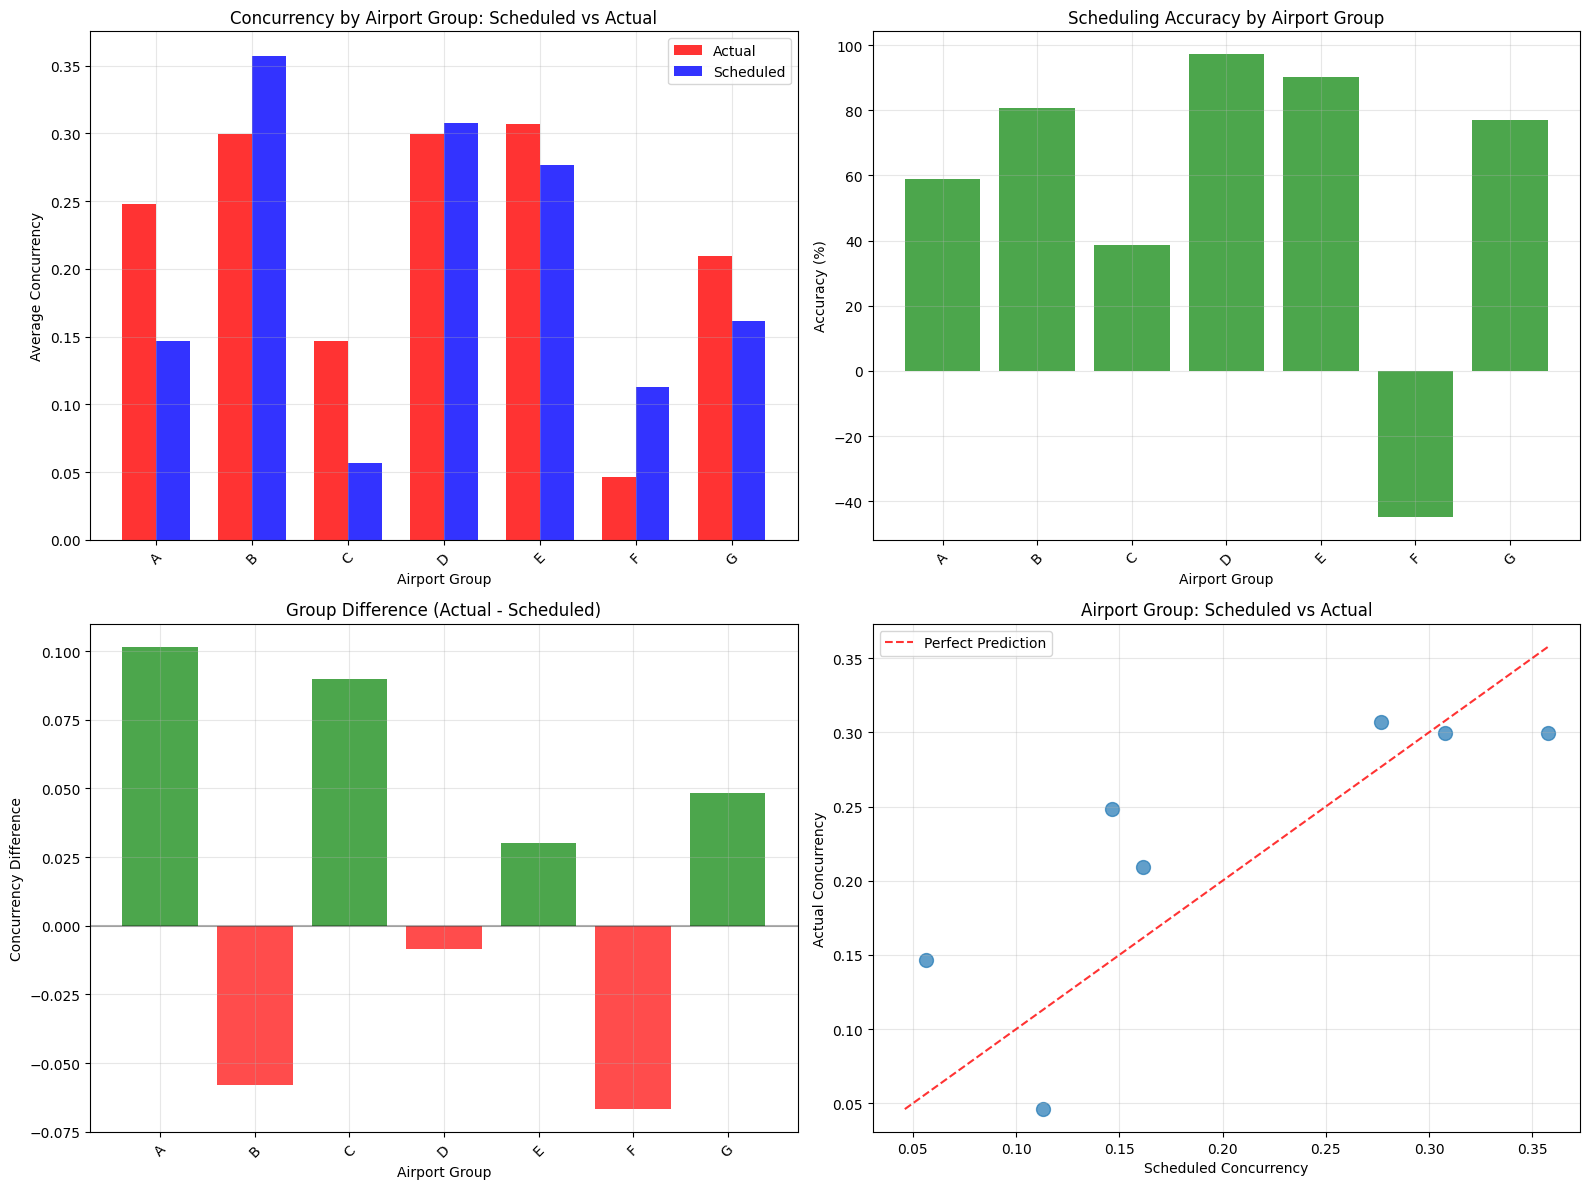


🌟 SEASONAL SCHEDULING ANALYSIS
-----------------------------------
Season Accuracy:
  autumn: 83.4%


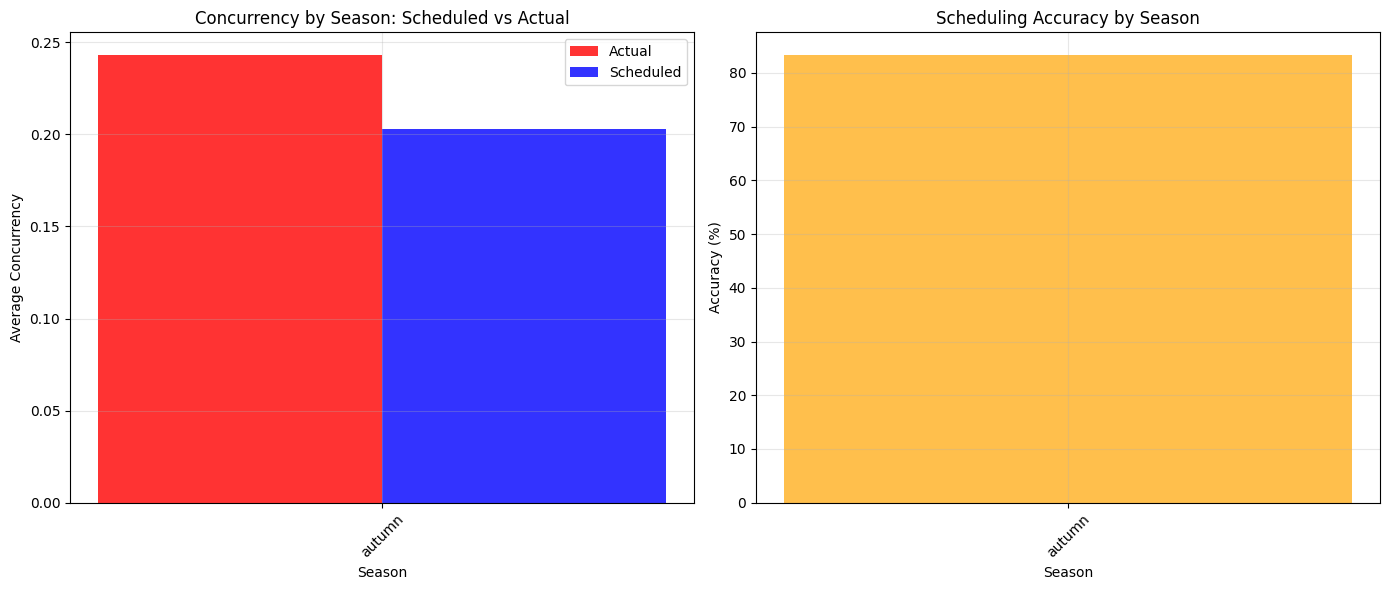

In [ ]:
# Airport Group Scheduling Analysis
print("\n🏢 AIRPORT GROUP SCHEDULING ANALYSIS")
print("-" * 45)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# Airport Group comparison using training vs inference data
actual_groups = actual_data.groupby('airport_group')['target'].mean()
sched_groups = sched_data.groupby('airport_group')['feat_sched_concurrence'].mean()

# Ensure we have matching airport groups
common_groups = actual_groups.index.intersection(sched_groups.index)
actual_groups_matched = actual_groups[common_groups]
sched_groups_matched = sched_groups[common_groups]

if len(common_groups) > 0:
    x_pos = range(len(common_groups))
    width = 0.35
    
    bars1 = ax1.bar([x - width/2 for x in x_pos], actual_groups_matched.values, 
                    width, label='Actual', alpha=0.8, color='red')
    bars2 = ax1.bar([x + width/2 for x in x_pos], sched_groups_matched.values, 
                    width, label='Scheduled', alpha=0.8, color='blue')
    ax1.set_title('Concurrency by Airport Group: Scheduled vs Actual')
    ax1.set_xlabel('Airport Group')
    ax1.set_ylabel('Average Concurrency')
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(common_groups, rotation=45)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Group accuracy
    group_accuracy = (1 - abs(actual_groups_matched - sched_groups_matched) / actual_groups_matched.replace(0, 0.1)) * 100
    ax2.bar(range(len(group_accuracy)), group_accuracy.values, alpha=0.7, color='green')
    ax2.set_title('Scheduling Accuracy by Airport Group')
    ax2.set_xlabel('Airport Group')
    ax2.set_ylabel('Accuracy (%)')
    ax2.set_xticks(range(len(group_accuracy)))
    ax2.set_xticklabels(group_accuracy.index, rotation=45)
    ax2.grid(True, alpha=0.3)
    
    print("Airport Group Accuracy:")
    for group, acc in group_accuracy.items():
        print(f"  Group {group}: {acc:.1f}%")
        
    # Group differences
    group_diff = actual_groups_matched - sched_groups_matched
    ax3.bar(range(len(group_diff)), group_diff.values, 
            color=['red' if x < 0 else 'green' for x in group_diff.values], alpha=0.7)
    ax3.set_title('Group Difference (Actual - Scheduled)')
    ax3.set_xlabel('Airport Group')
    ax3.set_ylabel('Concurrency Difference')
    ax3.set_xticks(range(len(group_diff)))
    ax3.set_xticklabels(group_diff.index, rotation=45)
    ax3.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax3.grid(True, alpha=0.3)
    
    # Scatter plot for groups
    ax4.scatter(sched_groups_matched.values, actual_groups_matched.values, alpha=0.7, s=100)
    min_val = min(min(sched_groups_matched.values), min(actual_groups_matched.values))
    max_val = max(max(sched_groups_matched.values), max(actual_groups_matched.values))
    if max_val > min_val:
        ax4.plot([min_val, max_val], [min_val, max_val], 'r--', alpha=0.8, label='Perfect Prediction')
    ax4.set_xlabel('Scheduled Concurrency')
    ax4.set_ylabel('Actual Concurrency')
    ax4.set_title('Airport Group: Scheduled vs Actual')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    
else:
    for i, ax in enumerate([ax1, ax2, ax3, ax4]):
        ax.text(0.5, 0.5, 'No matching airport\ngroup data available', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)
    print("No matching airport groups found between datasets")

plt.tight_layout()
plt.show()

# Season comparison
print("\n🌟 SEASONAL SCHEDULING ANALYSIS")
print("-" * 35)

# Season analysis
if 'feat_season' in actual_data.columns and 'feat_season' in sched_data.columns:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    actual_seasons = actual_data.groupby('feat_season')['target'].mean()
    sched_seasons = sched_data.groupby('feat_season')['feat_sched_concurrence'].mean()
    
    common_seasons = actual_seasons.index.intersection(sched_seasons.index)
    
    if len(common_seasons) > 0:
        actual_seasons_matched = actual_seasons[common_seasons]
        sched_seasons_matched = sched_seasons[common_seasons]
        
        x_pos = range(len(common_seasons))
        width = 0.35
        
        bars1 = ax1.bar([x - width/2 for x in x_pos], actual_seasons_matched.values, 
                        width, label='Actual', alpha=0.8, color='red')
        bars2 = ax1.bar([x + width/2 for x in x_pos], sched_seasons_matched.values, 
                        width, label='Scheduled', alpha=0.8, color='blue')
        ax1.set_title('Concurrency by Season: Scheduled vs Actual')
        ax1.set_xlabel('Season')
        ax1.set_ylabel('Average Concurrency')
        ax1.set_xticks(x_pos)
        ax1.set_xticklabels(common_seasons, rotation=45)
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Season accuracy
        season_accuracy = (1 - abs(actual_seasons_matched - sched_seasons_matched) / actual_seasons_matched.replace(0, 0.1)) * 100
        ax2.bar(range(len(season_accuracy)), season_accuracy.values, alpha=0.7, color='orange')
        ax2.set_title('Scheduling Accuracy by Season')
        ax2.set_xlabel('Season')
        ax2.set_ylabel('Accuracy (%)')
        ax2.set_xticks(range(len(season_accuracy)))
        ax2.set_xticklabels(season_accuracy.index, rotation=45)
        ax2.grid(True, alpha=0.3)
        
        print("Season Accuracy:")
        for season, acc in season_accuracy.items():
            print(f"  {season}: {acc:.1f}%")
    else:
        ax1.text(0.5, 0.5, 'No matching seasonal data', ha='center', va='center', transform=ax1.transAxes)
        ax2.text(0.5, 0.5, 'No matching seasonal data', ha='center', va='center', transform=ax2.transAxes)
        
    plt.tight_layout()
    plt.show()
else:
    print("Season data not available in both datasets")

In [ ]:
# Key Insights Summary
print("\n🎯 KEY SCHEDULING INSIGHTS")
print("=" * 50)

# Calculate overall metrics using training vs inference data
try:
    # For overall comparison, we need to ensure we're comparing like with like
    # Let's use a sample comparison approach
    
    # Get overall statistics from each dataset
    actual_mean = actual_data['target'].mean()
    sched_mean = sched_data['feat_sched_concurrence'].mean()
    
    actual_std = actual_data['target'].std()
    sched_std = sched_data['feat_sched_concurrence'].std()
    
    print(f"📊 Overall Dataset Comparison:")
    print(f"   • Actual concurrency average: {actual_mean:.3f}")
    print(f"   • Scheduled concurrency average: {sched_mean:.3f}")
    print(f"   • Difference: {actual_mean - sched_mean:+.3f}")
    print(f"   • Actual std deviation: {actual_std:.3f}")
    print(f"   • Scheduled std deviation: {sched_std:.3f}")
    
    # Distribution comparison
    print(f"\n📈 Distribution Analysis:")
    actual_nonzero = (actual_data['target'] > 0).sum()
    sched_nonzero = (sched_data['feat_sched_concurrence'] > 0).sum()
    
    print(f"   • Actual non-zero concurrency periods: {actual_nonzero} ({actual_nonzero/len(actual_data)*100:.1f}%)")
    print(f"   • Scheduled non-zero concurrency periods: {sched_nonzero} ({sched_nonzero/len(sched_data)*100:.1f}%)")
    
    # Hour-based insights
    if len(common_hours) > 1:
        peak_actual = actual_hourly.idxmax()
        peak_sched = sched_hourly.idxmax()
        
        print(f"\n🕐 Peak Hours Analysis:")
        print(f"   • Actual peak hour: {peak_actual} ({actual_hourly[peak_actual]:.3f} avg concurrency)")
        print(f"   • Scheduled peak hour: {peak_sched} ({sched_hourly[peak_sched]:.3f} avg concurrency)")
        
        if peak_actual == peak_sched:
            print(f"   • ✅ Peak hours match - good scheduling alignment")
        else:
            print(f"   • ⚠️ Peak hours differ - potential scheduling misalignment")
    
    # Airport group insights
    if len(common_groups) > 0:
        busiest_actual_group = actual_groups_matched.idxmax()
        busiest_sched_group = sched_groups_matched.idxmax()
        
        print(f"\n🏢 Airport Group Analysis:")
        print(f"   • Busiest actual group: {busiest_actual_group} ({actual_groups_matched[busiest_actual_group]:.3f})")
        print(f"   • Busiest scheduled group: {busiest_sched_group} ({sched_groups_matched[busiest_sched_group]:.3f})")
    
    print(f"\n💡 Key Recommendations:")
    
    if actual_mean > sched_mean * 1.1:
        print(f"   • 📈 Actual concurrency significantly higher than scheduled - consider capacity planning")
    elif sched_mean > actual_mean * 1.1:
        print(f"   • 📉 Scheduled concurrency higher than actual - potential over-scheduling")
    else:
        print(f"   • ✅ Reasonable alignment between scheduled and actual concurrency levels")
    
    if actual_std > sched_std * 1.5:
        print(f"   • 📊 High variability in actual vs scheduled - unpredictable demand patterns")
    
    print(f"   • 🔍 Focus on periods with highest concurrency for safety and efficiency")
    print(f"   • 🎯 Consider predictive models to better align scheduling with actual demand")
    print(f"   • 📅 Implement dynamic scheduling adjustments based on historical patterns")
    
except Exception as e:
    print(f"Error in insights calculation: {e}")
    print("Basic comparison between training and inference datasets completed.")

# Final summary visualization
print(f"\n📋 ANALYSIS COMPLETE")
print("=" * 30)
print("This analysis compared historical actual concurrency patterns")
print("with scheduled concurrency patterns to identify optimization opportunities.")
print("Use these insights to improve flight scheduling and resource allocation.")


🎯 KEY SCHEDULING INSIGHTS
📊 Overall Dataset Comparison:
   • Actual concurrency average: 0.222
   • Scheduled concurrency average: 0.203
   • Difference: +0.019
   • Actual std deviation: 0.416
   • Scheduled std deviation: 0.402

📈 Distribution Analysis:
   • Actual non-zero concurrency periods: 103353 (22.2%)
   • Scheduled non-zero concurrency periods: 1056 (20.3%)

🕐 Peak Hours Analysis:
   • Actual peak hour: 16 (0.385 avg concurrency)
   • Scheduled peak hour: 18 (0.581 avg concurrency)
   • ⚠️ Peak hours differ - potential scheduling misalignment

🏢 Airport Group Analysis:
   • Busiest actual group: E (0.307)
   • Busiest scheduled group: B (0.358)

💡 Key Recommendations:
   • ✅ Reasonable alignment between scheduled and actual concurrency levels
   • 🔍 Focus on periods with highest concurrency for safety and efficiency
   • 🎯 Consider predictive models to better align scheduling with actual demand
   • 📅 Implement dynamic scheduling adjustments based on historical patterns

📋 